# PowerPulse Kenya: Forecasting Monthly Electricity Sales with Time Series Analysis and Machine Learning
**Final Data Science Capstone Project - Annette Chege**

---
## How to read this notebook
Every step follows the same pattern: **what we are doing -> why we are doing it -> the code and its output -> what we found.** Nothing is hidden: where the data are uncertain, where a model fails, or where a result is not statistically convincing, the notebook says so.

| Stage | Section | Project objective |
|---|---|---|
| 1 | Data triage, combining and verification | Obj. 1 |
| 2 | Defining the target and forecast objective | Reviewer points 2, 3 |
| 3 | Exploratory data analysis | Obj. 2 |
| 4 | Statistical analysis and unusual observations | Obj. 2 |
| 5 | Evaluation design (train / validation / test, rolling origin) | Reviewer point 6 |
| 6 | Baselines + SARIMA + ETS + Linear regression + Random forest + extra ML + Neural net + Ensemble | Obj. 3, 4 |
| 7 | Evaluation, significance tests, error analysis | Obj. 5 |
| 8 | Uncertainty, explainability and the final forecast | Reviewer point 7, Obj. 6 |
| 9 | Conclusions, limitations, next steps | Research questions 1-5 |

### Where each piece of reviewer feedback is addressed
| Reviewer comment | Where / how it is handled |
|---|---|
| Limited data | Series extended from 27 to **87 months** (Jan 2019 - Mar 2026); provenance of every month is tracked (Section 1) |
| Target definition | Section 2 defines *KPLC sales* (GWh) and separates it from consumption and demand |
| Forecast horizon | **12 months ahead**, evaluated at every horizon 1-12 (Section 2) |
| Models and baselines | 3 baselines + 6 families, **all** compared on identical data splits (Section 6-7) |
| Data leakage | Chronological splits, expanding-window rolling origin, features built only from data available at the forecast origin (Section 5-6) |
| Deep learning | A regularised neural network (MLP) is tested as an *additional experiment* (Section 6); an LSTM is discussed in Section 9 |
| Error analysis | By horizon, by month, by period, plus a sensitivity analysis of the May-June 2025 anomaly (Section 7) |
| Explainability | Coefficients, ETS components, random-forest importances, prediction intervals, actual-vs-predicted (Section 8) |

---
# Stage 0 - Setup
The forecasting models, the data-combining logic and the evaluation functions live in one file, `powerpulse_core.py`, so that **this notebook, the Streamlit dashboard and the slides all use exactly the same code and therefore report exactly the same numbers.**

*Design note:* SARIMA and Holt-Winters ETS are implemented inside `powerpulse_core.py` (conditional-sum-of-squares SARIMA and damped/undamped additive Holt-Winters) using only `numpy`, `scipy` and `scikit-learn`. If `statsmodels` is installed, a cross-check cell near the end compares the two implementations.

In [8]:
import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
from scipy import stats
import powerpulse_core as pc

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
NAVY, TEAL, AMBER, RED, GREY = "#12355B", "#1B998B", "#F2A541", "#C0392B", "#8A9BA8"
Path("outputs/figs").mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(f"outputs/figs/{name}.png", dpi=170, bbox_inches="tight")
SLIDE = {}   # numbers collected here are re-used by the slides and the Streamlit app
print("Libraries loaded. Target =", pc.TARGET, "| forecast horizon =", pc.H_MAX, "months")

Libraries loaded. Target = kplc_sales_gwh | forecast horizon = 12 months


---
# Stage 1 - Data collection, triage and combining

## 1.1 Where the data come from
All figures are monthly **KPLC electricity sales in GWh (million kWh)**, taken from **Table 15(b) "Generation and Consumption of Electricity"** in the *Kenya National Bureau of Statistics (KNBS) Leading Economic Indicators* reports. Values were transcribed into CSV files with Python/pandas, and the source report of each block of months was recorded.

## 1.2 Which of the seven CSV files should be combined?
Two different operations exist, and they must not be confused:
* **Concatenate (stack rows)** - files that hold the *same kind of information for different months*. This is what the three source files are.
* **Merge/join (add columns)** - files holding *different variables for the same dates*. Generation, imports and exports exist only from 2024, so they cannot be joined onto the full series without creating thousands of artificial gaps; they are kept for analysis of the 2024-2026 period only.

Four of the seven files are **not** raw data - they are earlier *outputs* of this project (an audit copy, a working concatenation, an anomaly report and a verification register). Stacking them with the sources would duplicate months and silently inflate the sample, so each was **tested** against the sources and then excluded:

In [13]:
ref = Path("data/reference")
h1 = pd.read_csv("data/" + pc.SOURCE_FILES["hist_2019_2021"], parse_dates=["date"])
h2 = pd.read_csv("data/" + pc.SOURCE_FILES["hist_2022_2023"], parse_dates=["date"])
mm = pd.read_csv("data/" + pc.SOURCE_FILES["master_2024_2026"], parse_dates=["date"])
f_audit = pd.read_csv(ref / "powerpulse_historical_2019_2023_AUDIT_ONLY.csv", parse_dates=["date"])
f_comb  = pd.read_csv(ref / "powerpulse_combined_WORKING_NOT_FINAL.csv", parse_dates=["date"])
f_anom  = pd.read_csv(ref / "powerpulse_anomaly_review.csv", parse_dates=["date"])
f_reg   = pd.read_csv(ref / "powerpulse_historical_verification_register.csv", parse_dates=["date"])

# Evidence for each decision (computed, not assumed)
audit_is_h1h2 = f_audit[["date", pc.TARGET]].reset_index(drop=True).equals(
    pd.concat([h1, h2])[["date", pc.TARGET]].sort_values("date").reset_index(drop=True))
comb_same_sales = f_comb.sort_values("date")[pc.TARGET].round(2).tolist() == \
    pd.concat([h1, h2, mm]).sort_values("date")[pc.TARGET].round(2).tolist()
anom_same_sales = f_anom.sort_values("date")[pc.TARGET].round(2).tolist() == f_comb.sort_values("date")[pc.TARGET].round(2).tolist()
reg_all_unchecked = (f_reg["verification_status"] == "needs_source_check").all() and f_reg["verified_value_gwh"].isna().all()

triage = pd.DataFrame([
  ["powerpulse_historical_sales_candidates_2019_2021.csv", len(h1), "Monthly sales 2019-2021 + source report", "COMBINE", "Unique months, per-row source report"],
  ["powerpulse_historical_2022_2023_candidates.csv", len(h2), "Monthly sales 2022-2023 + source", "COMBINE", "Unique months, continues the series"],
  ["powerpulse_master_v1_2024-2026.csv", len(mm), "Sales 2024-Mar 2026 + generation/imports/exports + verification notes", "COMBINE (authoritative)", "Only file with verification status; wins any overlap"],
  ["powerpulse_historical_2019_2023_AUDIT_ONLY.csv", len(f_audit), "Date + sales only", "EXCLUDE", f"Identical copy of the two historical files (identical = {audit_is_h1h2}); using it would double-count 60 months"],
  ["powerpulse_combined_WORKING_NOT_FINAL.csv", len(f_comb), "Earlier working concatenation", "EXCLUDE (superseded)", f"Same sales as the three source files (same = {comb_same_sales}); loses the source URLs and notes"],
  ["powerpulse_anomaly_review.csv", len(f_anom), "Analysis OUTPUT: change %, YoY %, flags", "EXCLUDE (derived)", f"Derived columns, same sales (same = {anom_same_sales}); re-computed in this notebook instead"],
  ["powerpulse_historical_verification_register.csv", len(f_reg), "Audit template for 2019-2023", "KEEP SEPARATE (metadata)", f"All 60 rows still 'needs_source_check' with no verified value (all unchecked = {reg_all_unchecked})"],
], columns=["file", "rows", "what it contains", "decision", "evidence / reason"])
triage

,file,rows,what it contains,decision,evidence / reason
0,powerpulse_historical_sales_candidates_2019_20...,36,Monthly sales 2019-2021 + source report,COMBINE,"Unique months, per-row source report"
1,powerpulse_historical_2022_2023_candidates.csv,24,Monthly sales 2022-2023 + source,COMBINE,"Unique months, continues the series"
2,powerpulse_master_v1_2024-2026.csv,27,Sales 2024-Mar 2026 + generation/imports/expor...,COMBINE (authoritative),Only file with verification status; wins any o...
3,powerpulse_historical_2019_2023_AUDIT_ONLY.csv,60,Date + sales only,EXCLUDE,Identical copy of the two historical files (id...
4,powerpulse_combined_WORKING_NOT_FINAL.csv,87,Earlier working concatenation,EXCLUDE (superseded),Same sales as the three source files (same = T...
5,powerpulse_anomaly_review.csv,87,"Analysis OUTPUT: change %, YoY %, flags",EXCLUDE (derived),"Derived columns, same sales (same = True); re-..."
6,powerpulse_historical_verification_register.csv,60,Audit template for 2019-2023,KEEP SEPARATE (metadata),All 60 rows still 'needs_source_check' with no...


In [12]:
import os, shutil
from pathlib import Path

project = Path(r"C:\Users\HP\Desktop\FINAL-DATA-SCIENCE-CAPSTONE-PROJECT")
os.chdir(project)                      # always run from the project folder
print("Working folder:", Path.cwd())

wanted = {
  "data": ["powerpulse_historical_sales_candidates_2019_2021.csv",
           "powerpulse_historical_2022_2023_candidates.csv",
           "powerpulse_master_v1_2024-2026.csv"],
  "data/reference": ["powerpulse_historical_2019_2023_AUDIT_ONLY.csv",
                     "powerpulse_combined_WORKING_NOT_FINAL.csv",
                     "powerpulse_anomaly_review.csv",
                     "powerpulse_historical_verification_register.csv"],
}
for folder, names in wanted.items():
    Path(folder).mkdir(parents=True, exist_ok=True)
    for n in names:
        target = Path(folder) / n
        if target.exists():
            print("OK      ", target); continue
        hits = [p for p in project.rglob(n) if "powerpulse_capstone" not in p.parts or True]
        hits = [p for p in hits if p.resolve() != target.resolve()]
        if hits:
            shutil.copy(hits[0], target)
            print("COPIED  ", hits[0], "->", target)
        else:
            print("MISSING ", n, "  <- copy this file into", folder)

Working folder: C:\Users\HP\Desktop\FINAL-DATA-SCIENCE-CAPSTONE-PROJECT
COPIED   C:\Users\HP\Desktop\FINAL-DATA-SCIENCE-CAPSTONE-PROJECT\powerpulse_historical_sales_candidates_2019_2021.csv -> data\powerpulse_historical_sales_candidates_2019_2021.csv
COPIED   C:\Users\HP\Desktop\FINAL-DATA-SCIENCE-CAPSTONE-PROJECT\powerpulse_historical_2022_2023_candidates.csv -> data\powerpulse_historical_2022_2023_candidates.csv
COPIED   C:\Users\HP\Desktop\FINAL-DATA-SCIENCE-CAPSTONE-PROJECT\powerpulse_master_v1_2024-2026.csv -> data\powerpulse_master_v1_2024-2026.csv
COPIED   C:\Users\HP\Desktop\FINAL-DATA-SCIENCE-CAPSTONE-PROJECT\powerpulse_historical_2019_2023_AUDIT_ONLY.csv -> data\reference\powerpulse_historical_2019_2023_AUDIT_ONLY.csv
COPIED   C:\Users\HP\Desktop\FINAL-DATA-SCIENCE-CAPSTONE-PROJECT\powerpulse_combined_WORKING_NOT_FINAL.csv -> data\reference\powerpulse_combined_WORKING_NOT_FINAL.csv
COPIED   C:\Users\HP\Desktop\FINAL-DATA-SCIENCE-CAPSTONE-PROJECT\powerpulse_anomaly_review.csv 

In [5]:
import os
print(os.getcwd())
print(os.listdir("."))

c:\Users\HP\Desktop\FINAL-DATA-SCIENCE-CAPSTONE-PROJECT
['.git', 'app.py', 'historical_data.ipynb', 'outputs', 'PowerPulse_Capstone.ipynb', 'powerpulse_core.py', 'powerpulse_final_dataset.csv', 'powerpulse_historical_2022_2023_candidates.csv', 'powerpulse_historical_sales_candidates_2019_2021.csv', 'powerpulse_master_v1_2024-2026.csv', 'README_PROJECT.md', 'requirements.txt', '__pycache__']


In [6]:
import shutil
from pathlib import Path

root = Path(".")
(root / "data" / "reference").mkdir(parents=True, exist_ok=True)

# the three source files + the final dataset go in data/
for f in ["powerpulse_historical_sales_candidates_2019_2021.csv",
          "powerpulse_historical_2022_2023_candidates.csv",
          "powerpulse_master_v1_2024-2026.csv",
          "powerpulse_final_dataset.csv"]:
    if (root / f).exists():
        shutil.move(str(root / f), str(root / "data" / f))

# the four reference files, if they are anywhere in this folder
for f in ["powerpulse_anomaly_review.csv",
          "powerpulse_combined_WORKING_NOT_FINAL.csv",
          "powerpulse_historical_2019_2023_AUDIT_ONLY.csv",
          "powerpulse_historical_verification_register.csv"]:
    if (root / f).exists():
        shutil.move(str(root / f), str(root / "data" / "reference" / f))

print(sorted(p.as_posix() for p in (root / "data").rglob("*.csv")))

['data/powerpulse_final_dataset.csv', 'data/powerpulse_historical_2022_2023_candidates.csv', 'data/powerpulse_historical_sales_candidates_2019_2021.csv', 'data/powerpulse_master_v1_2024-2026.csv']


## 1.3 Combining the three source files
We now concatenate the three non-overlapping source files into one table, apply the overlap rule, and run the quality checks the proposal promised: date range, missing months, duplicates, missing values, unit consistency.

In [14]:
df, audit = pc.build_dataset("data")
for k, v in audit.items():
    print(f"{k:28s}: {v}")
assert audit["duplicate_dates"] == 0 and audit["missing_sales"] == 0 and not audit["missing_months"]
y = df.set_index("date")[pc.TARGET]; y.index.freq = "MS"
df.to_csv("data/powerpulse_final_dataset.csv", index=False)
print("\nSaved data/powerpulse_final_dataset.csv  ->", df.shape)
df[["date", pc.TARGET, "reliability", "origin_file", "period"]].groupby(["period", "reliability"]).agg(
    months=("date", "size"), first=("date", "min"), last=("date", "max"))

rows_stacked                : 87
overlapping_dates_resolved  : 0
rows_final                  : 87
start                       : 2019-01-01 00:00:00
end                         : 2026-03-01 00:00:00
missing_months              : []
duplicate_dates             : 0
missing_sales               : 0
non_positive_sales          : 0
all_month_start             : True
unit                        : GWh (million kWh)

Saved data/powerpulse_final_dataset.csv  -> (87, 15)


months      first       last
period                    reliability                                         
2019-2023 (candidate)     candidate_unverified        60 2019-01-01 2023-12-01
2024-2026 (KNBS verified) verified                    21 2024-01-01 2025-12-01
                          verified_but_anomalous       2 2025-05-01 2025-06-01
                          verified_provisional         3 2026-01-01 2026-03-01
                          verified_target_2src         1 2024-11-01 2024-11-01

**What this shows.** The three source files contain 36 + 24 + 27 = **87 distinct months** with **no overlapping dates**, so no value had to be discarded. The *overlap rule* is nevertheless coded for safety: if a month ever appeared twice, the KNBS master file (verified, newest vintage) wins over the 2022-23 file, which wins over the 2019-21 file.

**Why we keep a `reliability` flag.** Only the 2024-2026 data carry KNBS verification notes:
* 60 months (2019-2023) are still **candidates** - transcribed from KNBS tables but not yet cross-checked against later report vintages. We use them (the project needs a long series) but flag them and **test how much they matter**.
* 21 + 1 months are **verified** (the Nov-2024 value was recovered from two sources because KNBS omitted that row in two later tables).
* 2 months (May and June 2025) are **verified but anomalous**.
* 3 months (Jan-Mar 2026) are **provisional** and may be revised by KNBS.

> **Honesty statement.** The 2019-2023 values are *collected*, not *independently verified*; the verification register still shows every one of those 60 months as `needs_source_check`. All conclusions are therefore conditional on those figures being correct. Verifying them against the original PDFs is the first recommended next step.

---
# Stage 2 - What exactly are we forecasting?

## 2.1 Sales, consumption and demand are three different things
| Concept | Meaning | In this project? |
|---|---|---|
| **KPLC electricity sales** | Energy *sold/billed* to KPLC customers, in GWh per month | **Yes - our target** |
| Electricity consumption | Energy actually *used* by everybody, including users outside KPLC's billing and energy lost in the network | No |
| Demand | Instantaneous *power* required, in MW (peak demand) | No |

KNBS reports sales within the table titled "Generation and Consumption of Electricity". Because a share of the electricity supplied is lost or unbilled, sales are always lower than supply. The next cell measures that relationship for 2024-2026, the only period where supply (generation + imports) is available, and it will turn out to be important for judging the May-June 2025 anomaly.

## 2.2 Forecast objective
* **Horizon: 12 months ahead** (also reported at 1, 3 and 6 months).
* **Practical purpose:** an annual planning view for budgeting energy purchases and generation dispatch, revenue planning, and the pacing of grid investment. Short horizons (1-3 months) support operational scheduling; the 12-month horizon supports budgeting.
* **Metric choice:** MAE (average error in GWh, easy to explain), RMSE (penalises large misses), MAPE (percentage) and MASE (error relative to a seasonal-naive forecast; MASE < 1 means better than that benchmark in the training period).

In [15]:
sup = df.dropna(subset=["total_generation_and_imports_gwh"]).copy()
sup["sales_share_of_supply"] = sup[pc.TARGET] / sup["total_generation_and_imports_gwh"]
sup["z"] = pc.robust_z(sup["sales_share_of_supply"])
print("Sales as a share of electricity supplied (generation + imports), 2024-2026:")
print(sup["sales_share_of_supply"].describe().round(3).to_string())
print("\nMonths where the ratio is unusual (|robust z| > 3.5):")
print(sup.loc[sup["z"].abs() > 3.5, ["date", pc.TARGET, "total_generation_and_imports_gwh", "sales_share_of_supply", "z"]].round(3).to_string(index=False))

Sales as a share of electricity supplied (generation + imports), 2024-2026:
count    27.000
mean      0.773
std       0.033
min       0.725
25%       0.753
50%       0.770
75%       0.778
max       0.903

Months where the ratio is unusual (|robust z| > 3.5):
      date  kplc_sales_gwh  total_generation_and_imports_gwh  sales_share_of_supply     z
2025-06-01         1090.88                           1208.66                  0.903 5.511


---
# Stage 3 - Exploratory data analysis (EDA)

## 3.1 The long-run trend

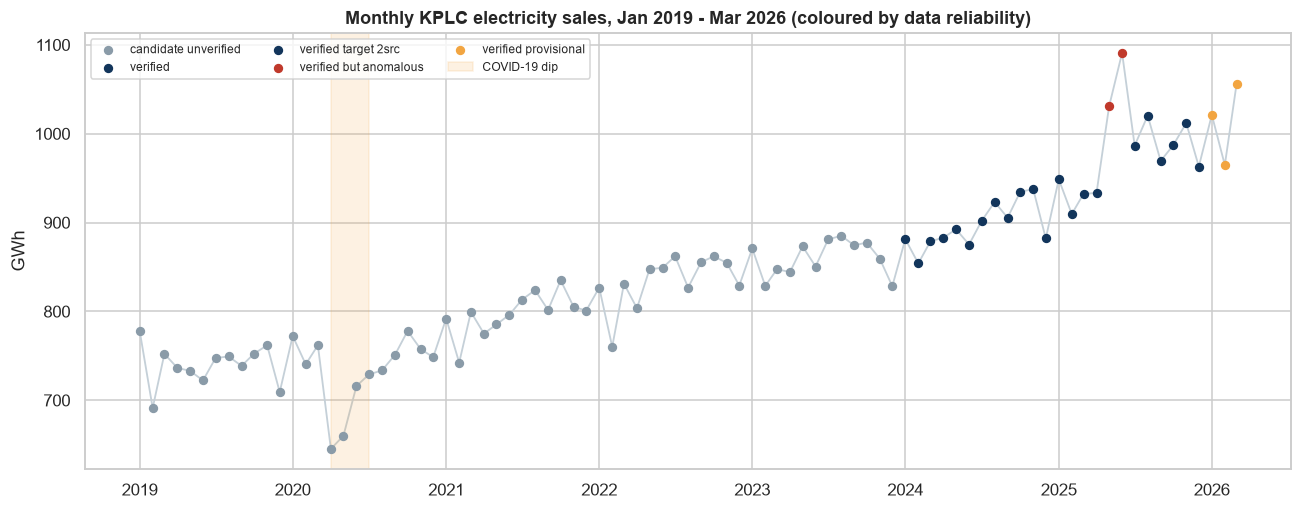

,mean,min,max,count,growth_vs_prev_year_pct
year,,,,,
2019,739.4,691.3,778.1,12,NaN
2020,732.9,645.3,778.0,12,-0.9
2021,797.5,742.3,835.1,12,8.8
2022,834.0,760.2,862.0,12,4.6
2023,860.1,828.3,885.2,12,3.1
2024,895.8,854.0,937.7,12,4.2
2025,982.0,909.5,1090.9,12,9.6
2026,1013.9,964.7,1055.7,3,3.2


In [16]:
fig, ax = plt.subplots(figsize=(12, 4.8))
cols = {"candidate_unverified": GREY, "verified": NAVY, "verified_target_2src": NAVY,
        "verified_but_anomalous": RED, "verified_provisional": AMBER}
ax.plot(df["date"], df[pc.TARGET], color="#c5d0d8", lw=1.2, zorder=1)
for r, c in cols.items():
    s = df[df["reliability"] == r]
    ax.scatter(s["date"], s[pc.TARGET], color=c, s=26, zorder=3, label=r.replace("_", " "))
ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2020-06-30"), color=AMBER, alpha=0.15, label="COVID-19 dip")
ax.set_title("Monthly KPLC electricity sales, Jan 2019 - Mar 2026 (coloured by data reliability)")
ax.set_ylabel("GWh"); ax.legend(ncol=3, fontsize=8, frameon=True, loc="upper left")
savefig("01_sales_trend"); plt.show()

annual = df.groupby("year")[pc.TARGET].agg(["mean", "min", "max", "count"]).round(1)
annual["growth_vs_prev_year_pct"] = (annual["mean"].pct_change() * 100).round(1)
annual

**Finding - trend.** Sales rose from an average of 739.4 GWh/month in 2019 to 982.0 GWh/month in 2025 (+32.8%). Growth was interrupted in 2020 (-0.9%, COVID-19), rebounded strongly in 2021 (+8.8%), then ran at a steady 3-5% a year in 2022-2024 before jumping to **+9.6% in 2025**. The trend is clearly **upward and not constant**, which already tells us that a model that cannot adapt to a changing growth rate will fall behind.

## 3.2 Seasonality

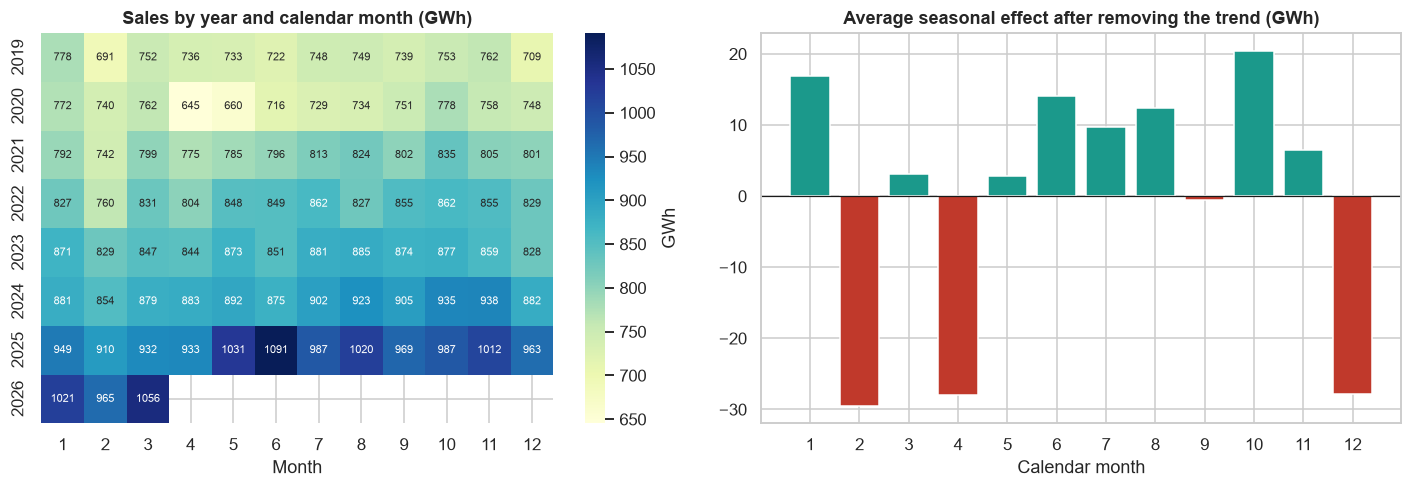

Seasonal effect by month (GWh):
date
1     16.9
2    -29.5
3      3.1
4    -28.0
5      2.8
6     14.1
7      9.6
8     12.4
9     -0.5
10    20.4
11     6.5
12   -27.9


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
piv = df.pivot(index="year", columns="month_num", values=pc.TARGET)
sns.heatmap(piv, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "GWh"}, ax=axes[0], annot_kws={"size": 7})
axes[0].set_title("Sales by year and calendar month (GWh)"); axes[0].set_xlabel("Month"); axes[0].set_ylabel("")
dec = pc.classical_decomposition(y)
seas = dec["seasonal"].groupby(dec.index.month).first()
axes[1].bar(seas.index, seas.values, color=[TEAL if v >= 0 else RED for v in seas.values])
axes[1].set_xticks(range(1, 13)); axes[1].set_title("Average seasonal effect after removing the trend (GWh)")
axes[1].set_xlabel("Calendar month"); axes[1].axhline(0, color="k", lw=0.8)
savefig("02_seasonality"); plt.show()
print("Seasonal effect by month (GWh):"); print(seas.round(1).to_string())

**Finding - seasonality.** The calendar pattern is consistent from year to year: **January, June, August, October** are high; **February, April and December** are low (December reflects the holiday shutdown of businesses and factories). The detrended seasonal swing is roughly +/-30 GWh around the trend, small compared with the +/-100 GWh the trend itself moves over a few years.

## 3.3 Is February low simply because it is a short month?
Months differ in length (28-31 days), which mechanically changes monthly totals. Dividing by the number of days gives **average daily sales**, which isolates real changes in electricity use from calendar length.

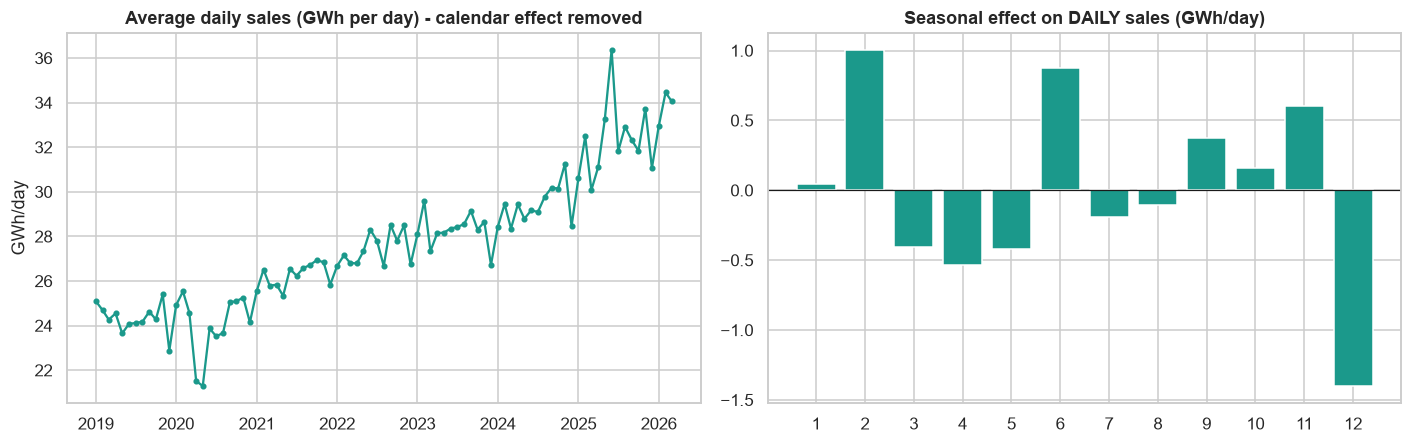

February vs January (average over years): total sales -5.9%  |  daily-average sales +3.3%
Pure calendar effect (28.25 vs 31 days): -8.9%


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(df["date"], df["sales_per_day_gwh"], color=TEAL, marker="o", ms=3)
axes[0].set_title("Average daily sales (GWh per day) - calendar effect removed"); axes[0].set_ylabel("GWh/day")
dec_d = pc.classical_decomposition(df.set_index("date")["sales_per_day_gwh"])
sd = dec_d["seasonal"].groupby(dec_d.index.month).first()
axes[1].bar(sd.index, sd.values, color=TEAL); axes[1].axhline(0, color="k", lw=.8)
axes[1].set_xticks(range(1, 13)); axes[1].set_title("Seasonal effect on DAILY sales (GWh/day)")
savefig("03_per_day"); plt.show()
feb_jan = (df[df.month_num == 2].set_index("year")[pc.TARGET] / df[df.month_num == 1].set_index("year")[pc.TARGET]).mean() - 1
feb_jan_day = (df[df.month_num == 2].set_index("year")["sales_per_day_gwh"] / df[df.month_num == 1].set_index("year")["sales_per_day_gwh"]).mean() - 1
print(f"February vs January (average over years): total sales {feb_jan*100:+.1f}%  |  daily-average sales {feb_jan_day*100:+.1f}%")
print(f"Pure calendar effect (28.25 vs 31 days): {(28.25/31-1)*100:+.1f}%")
SLIDE["feb_jan_pct"] = float(feb_jan*100); SLIDE["feb_jan_perday_pct"] = float(feb_jan_day*100)

**Finding - calendar effect.** February's total is about 5.9% below January's, *less* than the 8.9% a pure day-count would imply: **per day, February sales are actually about 3% higher than January's.** So part of the apparent seasonality is a calendar artefact, and part is genuine. This is why the machine-learning models in this project forecast *daily-average* sales and convert back to monthly totals - the learners then only have to predict genuine year-on-year growth, not the number of days in the month.

## 3.4 Decomposition into trend, seasonal and remainder
Classical additive decomposition splits each month into a smooth trend, a repeating seasonal effect, and a remainder. The remainder is where unusual events show up.

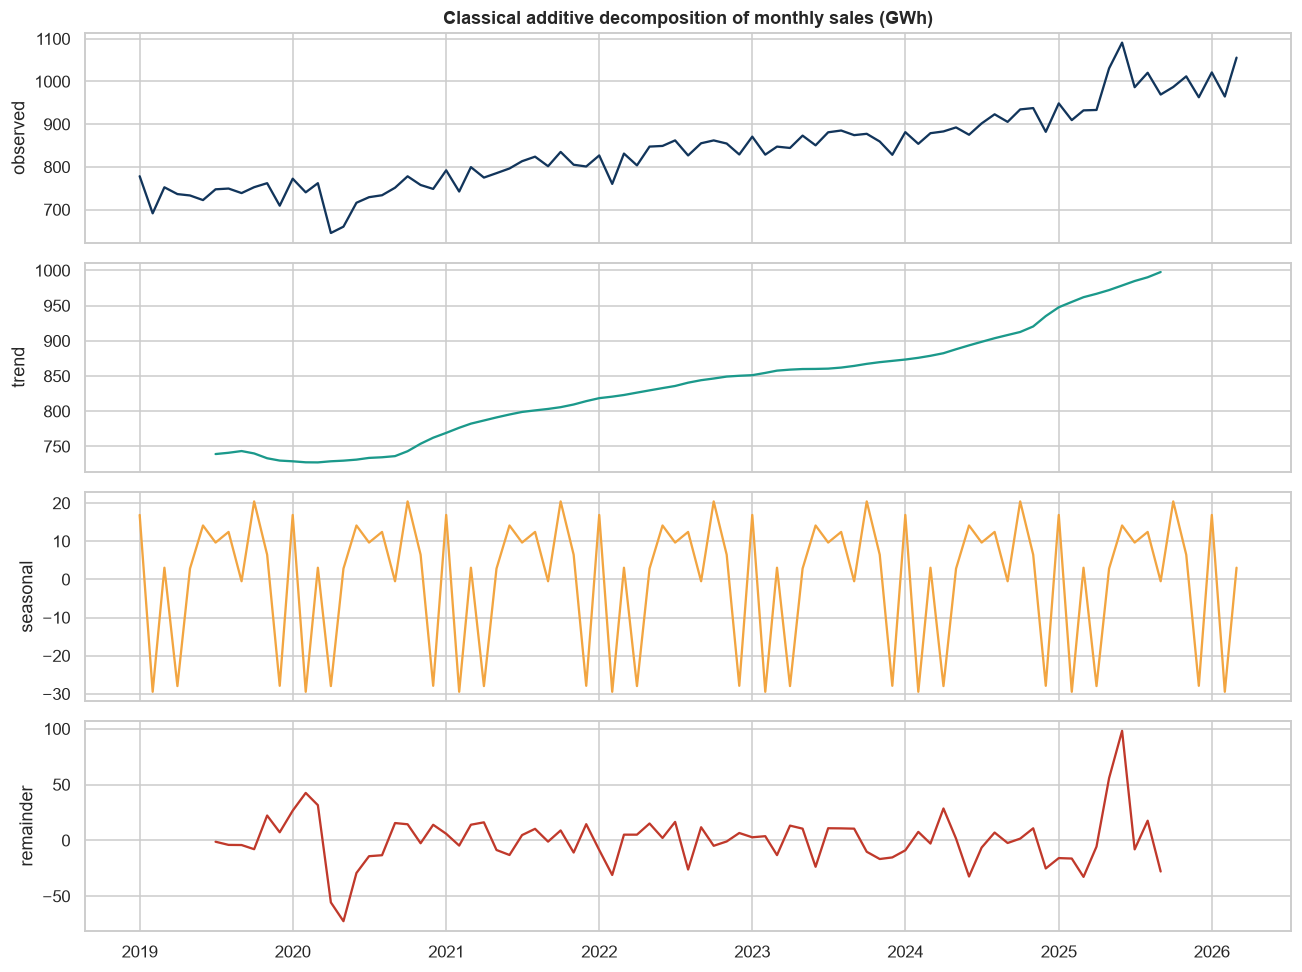

,observed,trend,seasonal,remainder
date,,,,
2025-06-01,1090.9,978.6,14.1,98.2
2020-05-01,660.1,729.8,2.8,-72.5
2025-05-01,1030.7,972.1,2.8,55.8
2020-04-01,645.3,728.9,-28.0,-55.6
2020-02-01,740.5,727.4,-29.5,42.5


In [19]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, col, c in zip(axes, ["observed", "trend", "seasonal", "remainder"], [NAVY, TEAL, AMBER, RED]):
    ax.plot(dec.index, dec[col], color=c); ax.set_ylabel(col)
axes[0].set_title("Classical additive decomposition of monthly sales (GWh)")
savefig("04_decomposition"); plt.show()
dec.dropna().assign(abs_rem=lambda d: d["remainder"].abs()).nlargest(5, "abs_rem")[["observed", "trend", "seasonal", "remainder"]].round(1)

**Finding - unusual months.** The largest remainders are **June 2025 (+98 GWh)**, **May 2020 (-72 GWh, COVID lockdown)**, **May 2025 (+56 GWh)** and April 2020 (-56 GWh). Two separate episodes dominate: the COVID-19 shock of April-June 2020 and the unexplained May-June 2025 surge.

## 3.5 Year-on-year change and outlier screening
Year-on-year comparison (same month, previous year) removes seasonality, so spikes stand out. We use a *robust* z-score (median and median-absolute-deviation) rather than a fixed 8% rule because it adapts to the series' normal variability.

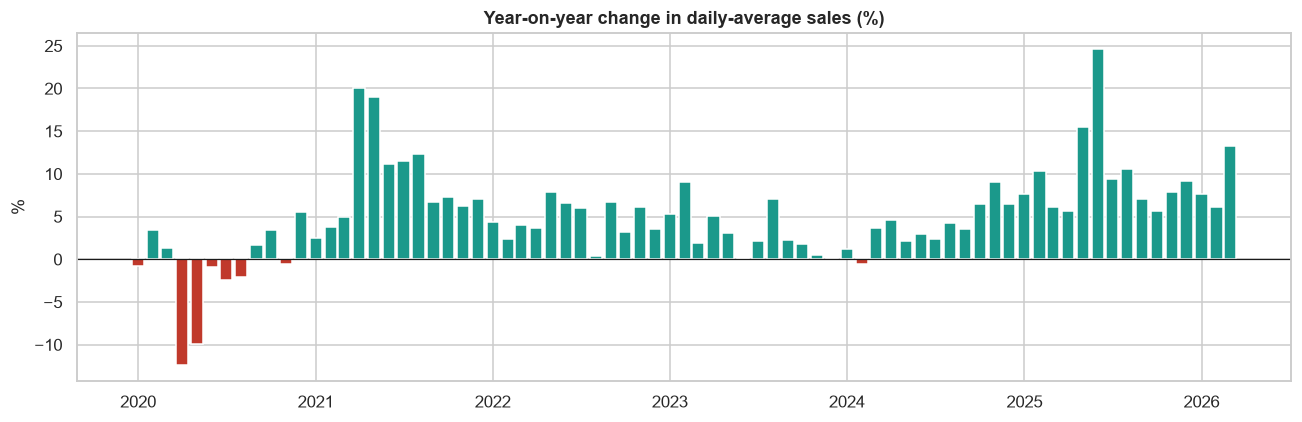

Months whose year-on-year growth is unusual (|robust z| > 3.5):
            kplc_sales_gwh  yoy_perday_pct  yoy_z
date                                             
2020-04-01          645.29          -12.37  -4.32
2020-05-01          660.11           -9.96  -3.72
2021-04-01          775.02           20.10   3.79
2021-05-01          785.36           18.97   3.51
2025-06-01         1090.88           24.63   4.92

Largest month-to-month moves:
date
2020-04-01    15.3
2019-02-01    11.2
2025-05-01    10.4
2025-07-01     9.6
2026-03-01     9.4
2022-03-01     9.3


In [20]:
d = df.set_index("date").copy()
d["mom_pct"] = d[pc.TARGET].pct_change() * 100
d["yoy_pct"] = d[pc.TARGET].pct_change(12) * 100
d["yoy_perday_pct"] = d["sales_per_day_gwh"].pct_change(12) * 100
d["yoy_z"] = pc.robust_z(d["yoy_perday_pct"].dropna())
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(d.index, d["yoy_perday_pct"], width=25, color=[RED if v < 0 else TEAL for v in d["yoy_perday_pct"].fillna(0)])
ax.axhline(0, color="k", lw=.8); ax.set_title("Year-on-year change in daily-average sales (%)"); ax.set_ylabel("%")
savefig("05_yoy"); plt.show()
print("Months whose year-on-year growth is unusual (|robust z| > 3.5):")
print(d.loc[d["yoy_z"].abs() > 3.5, [pc.TARGET, "yoy_perday_pct", "yoy_z"]].round(2).to_string())
print("\nLargest month-to-month moves:")
print(d["mom_pct"].abs().nlargest(6).round(1).to_string())

**Finding.** Five months are statistical outliers: April and May 2020 (COVID dip), April and May 2021 (the *mirror-image rebound* - they look like +20% growth only because the 2020 base is depressed) and June 2025 (+24.6%). The 2021 rebound matters for modelling: a learner trained on year-on-year growth would otherwise "learn" that April and May always grow by 20%. We therefore **mask COVID-distorted growth values from machine-learning training** (never from evaluation).

---
# Stage 4 - Statistical analysis

We test four things: (1) is the series stationary, (2) is seasonality statistically real, (3) did growth change, and (4) is the recent growth real or an artefact?

In [21]:
res_adf = {
    "level": pc.adf_test(y.values),
    "first difference": pc.adf_test(np.diff(y.values)),
    "seasonal difference (12)": pc.adf_test(y.values[12:] - y.values[:-12]),
    "first + seasonal difference": pc.adf_test(np.diff(y.values[12:] - y.values[:-12])),
}
adf_tab = pd.DataFrame({k: {"ADF statistic": v["adf_stat"], "5% critical": v["crit"]["5%"], "lags": v["lags"],
                            "nobs": v["nobs"], "stationary at 5%?": v["stationary_at_5pct"]} for k, v in res_adf.items()}).T
print(adf_tab.round(3).to_string())

# Seasonality: is the month-of-year pattern real?  Kruskal-Wallis on detrended values
detr = (dec["observed"] - dec["trend"]).dropna()
groups = [detr[detr.index.month == m].values for m in range(1, 13)]
kw = stats.kruskal(*groups)
print(f"\nKruskal-Wallis test for a month-of-year effect (detrended sales): H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}")

# Structural change: is growth after April 2025 different from before?
g = d["yoy_perday_pct"].dropna()
bad = pc._covid_contaminated_growth(d.index)
g_clean = d["yoy_perday_pct"][~bad].dropna()
pre, post = g_clean[g_clean.index < "2025-05-01"], g_clean[g_clean.index >= "2025-05-01"]
tt = stats.ttest_ind(post, pre, equal_var=False)
print(f"\nYoY growth, COVID-distorted months excluded: before May-2025 mean = {pre.mean():.2f}% (n={len(pre)}), "
      f"from May-2025 mean = {post.mean():.2f}% (n={len(post)}); Welch t = {tt.statistic:.2f}, p = {tt.pvalue:.4f}")

# Is the post-April-2025 growth real?  Compare with electricity SUPPLY growth over the same months
sup_g = df.set_index("date")["total_generation_and_imports_gwh"].pct_change(12) * 100
cmp_ = pd.DataFrame({"sales_yoy_%": d["yoy_pct"], "supply_yoy_%": sup_g}).loc["2025-01":].round(1)
print("\nSales vs supply year-on-year growth (2025-2026):"); print(cmp_.to_string())
SLIDE["adf_level_stat"] = res_adf["level"]["adf_stat"]; SLIDE["adf_level_crit5"] = res_adf["level"]["crit"]["5%"]
SLIDE["kw_p"] = float(kw.pvalue); SLIDE["pre_growth"] = float(pre.mean()); SLIDE["post_growth"] = float(post.mean())

                            ADF statistic 5% critical lags nobs stationary at 5%?
level                             0.69903    -2.90147   12   74             False
first difference                -2.610337    -2.90147   11   74             False
seasonal difference (12)        -3.705223    -2.90147    0   74              True
first + seasonal difference     -8.779534   -2.902607    1   72              True

Kruskal-Wallis test for a month-of-year effect (detrended sales): H = 33.9, p = 3.74e-04

YoY growth, COVID-distorted months excluded: before May-2025 mean = 4.16% (n=58), from May-2025 mean = 10.62% (n=11); Welch t = 3.76, p = 0.0030

Sales vs supply year-on-year growth (2025-2026):
            sales_yoy_%  supply_yoy_%
date                                 
2025-01-01          7.6           5.3
2025-02-01          6.5           1.9
2025-03-01          6.1           4.8
2025-04-01          5.7           7.0
2025-05-01         15.5           8.2
2025-06-01         24.6           6.2


**Findings.**
1. **Stationarity.** The raw series is **not stationary** (ADF statistic +0.70 vs a 5% critical value of -2.90) and a first difference alone is not enough (-2.61). Only after a **seasonal difference (12 months)** does it become stationary (-3.71), and a first + seasonal difference is comfortably stationary (-8.78). This is the statistical justification for the SARIMA structure used later, which differences once regularly and once seasonally (d = 1, D = 1). *(ADF uses MacKinnon critical values; the notebook's last cells show an optional statsmodels cross-check.)*
2. **Seasonality is real.** The Kruskal-Wallis test rejects "all calendar months are equal" (H = 33.9, p = 0.0004).
3. **Growth changed.** Mean year-on-year growth was **4.2%** before May 2025 and **10.6%** from May 2025 on (Welch t = 3.76, p = 0.003). The test includes the two anomalous months, so on its own it overstates the change.
4. **Is the 2025-26 growth real?** Comparing sales growth with supply growth (generation + imports) shows that **after the two anomalous months, sales growth (about 5-10%) moves in step with supply growth (about 6-13%)**, so the higher level since mid-2025 looks genuine. **May-June 2025 are different:** sales jumped 15.5% and 24.6% while supply rose only 8.2% and 6.2%, and sales as a share of supply hit 83% and 90% against a normal 77%. Those two months look like a **reporting or billing-timing effect rather than a real surge in electricity use** - but we have no external evidence, so we *neither delete nor alter them in the main analysis*, and instead measure how much they matter.

## 4.1 A sensitivity series for May-June 2025
To measure the influence of those two months, we create a clearly labelled *sensitivity* series where they are replaced by (typical sales share of supply) x (actual supply). **It is used only for comparison; every headline result uses the reported KNBS values.**

In [22]:
# A clearly-labelled SENSITIVITY series: May-Jun 2025 replaced by (typical sales share) x (supply).
# It is NOT used for the main results - only to test how much those two months drive the conclusions.
ratio = sup["sales_share_of_supply"]
typical = ratio[~sup["date"].isin(pd.to_datetime(["2025-05-01", "2025-06-01"]))].median()
y_adj = y.copy()
for dt in pd.to_datetime(["2025-05-01", "2025-06-01"]):
    y_adj.loc[dt] = typical * sup.set_index("date").loc[dt, "total_generation_and_imports_gwh"]
print(f"Typical sales share of supply (all other months): {typical:.3f}")
print(pd.DataFrame({"reported": y.loc["2025-04":"2025-07"], "sensitivity_value": y_adj.loc["2025-04":"2025-07"]}).round(1))

Typical sales share of supply (all other months): 0.769
            reported  sensitivity_value
date                                   
2025-04-01     933.3              933.3
2025-05-01    1030.7              958.7
2025-06-01    1090.9              929.5
2025-07-01     986.5              986.5


---
# Stage 5 - Evaluation design (prevents data leakage)

Time series cannot be shuffled: a model must never see the future. We therefore use **chronological** splits and a **rolling-origin (expanding-window)** evaluation:

* **Initial training:** Jan 2019 - Dec 2021 (36 months).
* **Validation window:** forecast targets from **Jan 2022 to Dec 2024.** All choices - which SARIMA order, damped or undamped ETS, which random-forest depth, which model is "best" - are made using *only* this window.
* **Final test window:** forecast targets from **Jan 2025 to Mar 2026** (15 months). Never used for any choice; it simulates real future use.
* **Rolling origin:** at each origin month the model is re-fitted on *all* data up to that month and forecasts the next 12 months. Every target month is therefore forecast at every horizon h = 1 ... 12 using only information available h months earlier. This gives 366 validation and 180 test forecast-target pairs per model.

**Leakage safeguards built into the code:** (a) each model only ever receives `y[:origin+1]`; (b) the machine-learning training rows are (origin, horizon) pairs whose *targets* also lie within that history; (c) feature scaling for the neural network is fitted on training rows only; (d) COVID-distorted growth values are removed from ML *training* only.

**A deliberately hard test.** The test window contains the 2025 growth acceleration and the May-June 2025 anomaly. Errors will therefore be larger than in validation - and that is informative, not a flaw.

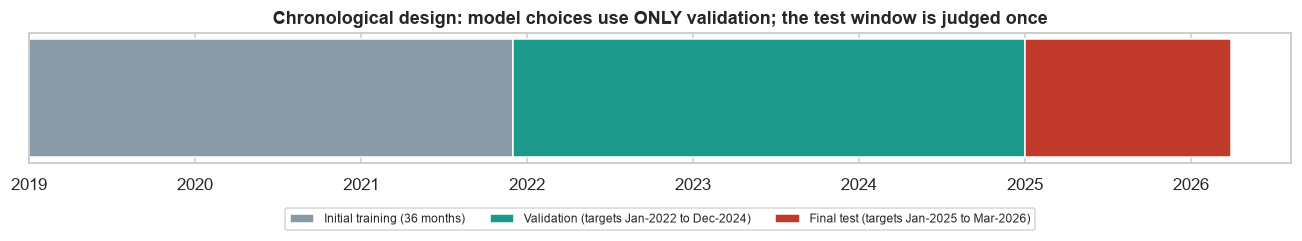

In [23]:
fig, ax = plt.subplots(figsize=(12, 2.6))
dates = df["date"]
ax.barh(0, (pd.Timestamp("2021-12-01") - dates.min()).days, left=dates.min(), color=GREY, height=.5, label="Initial training (36 months)")
ax.barh(0, (pd.Timestamp("2024-12-31") - pd.Timestamp("2021-12-01")).days, left=pd.Timestamp("2021-12-01"), color=TEAL, height=.5, label="Validation (targets Jan-2022 to Dec-2024)")
ax.barh(0, (dates.max() - pd.Timestamp("2025-01-01")).days + 30, left=pd.Timestamp("2025-01-01"), color=RED, height=.5, label="Final test (targets Jan-2025 to Mar-2026)")
ax.set_yticks([]); ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -0.3))
ax.set_title("Chronological design: model choices use ONLY validation; the test window is judged once")
savefig("06_split_design"); plt.show()

---
# Stage 6 - Models

Every model below is compared with **every other** and with three baselines on the same forecast-target pairs.

| Family | Model | Idea | Why include it |
|---|---|---|---|
| Baseline | **Naive** | Repeat the last value | Simplest benchmark |
| Baseline | **Seasonal naive** | Same month last year | Standard benchmark for seasonal data |
| Baseline | **Seasonal naive + drift** | Same month last year x trailing-12-month growth | A *strong* simple benchmark - any complex model must beat this to justify its complexity |
| Statistical | **ETS** (Holt-Winters, additive) | Smoothed level, trend and seasonal components; damped vs undamped chosen on validation | Interpretable components |
| Statistical | **SARIMA** | Seasonal ARIMA with d = 1, D = 1; three orders compared on validation | Justified by the ADF results |
| Regression | **Linear regression** | Linear time trend + month dummies (+ leap-year February) | Transparent, hard to overfit |
| Machine learning | **Random forest** | Direct multi-horizon forecast of year-on-year growth using lagged growth and calendar features | Lagged-feature ML, as in the proposal |
| Machine learning | **Gradient boosting** | Same features, boosted shallow trees | A second ML learner |
| Deep learning (extra) | **Neural net (MLP)** | One hidden layer of 16 tanh units, strongly regularised, 3-seed average | Additional experiment; see note below |
| Combination | **Ensemble** | Simple average of ETS, SARIMA, Linear regression, Random forest (the four candidates named in the proposal, fixed *before* looking at results) | Averages out the individual models' mistakes |

**Machine-learning set-up (no leakage).** For each (origin, horizon) pair the learner sees: year-on-year growth of daily-average sales at the origin and the two months before, the 6-month average growth, growth momentum, the horizon, and sine/cosine of the target month. The target is the log year-on-year growth for the target month, and the forecast is rebuilt as `sales per day one year earlier x exp(growth) x days in month`.

**On the neural network.** The reviewer suggested trying an LSTM only after reliable baselines and with caution because 87 monthly observations are very few. We follow that advice: the neural-network experiment uses a small multilayer perceptron on the same chronological protocol, and its regularisation strength was tuned on validation origins only (an un-regularised version was unstable, with validation MAE above 100 GWh). A full LSTM would need a deep-learning framework (TensorFlow or PyTorch) and, with so little data, is expected to overfit; it is listed as future work.

In [24]:
models = pc.candidate_models()
print("Candidate configurations:", list(models))
res_raw = pc.rolling_origin(y, models, verbose=False)
res_raw.to_csv("outputs/rolling_origin_all_candidates.csv", index=False)
print("Rolling-origin forecasts:", res_raw.shape, "| origins:", res_raw["origin_idx"].nunique())
print(res_raw.groupby("window")["error"].size().rename("forecast-target pairs").to_string())

Candidate configurations: ['Naive', 'Seasonal naive', 'Seasonal naive + drift', 'ETS_damped', 'ETS_undamped', 'SARIMA_A', 'SARIMA_B', 'SARIMA_C', 'Linear regression', 'RF_depth3', 'RF_depthNone', 'Gradient boosting', 'Neural net (MLP)']
Rolling-origin forecasts: (7098, 10) | origins: 51
window
development    4758
test           2340


---
# Stage 7 - Evaluation

## 7.0 Step one: choose configurations on the validation window only
Three model families come in several configurations (ETS damped/undamped, three SARIMA orders, two random-forest depths). We score every configuration on the **validation window only** and keep the best of each family; the test window plays no part in these choices. We then add the ensemble and compare all models on validation and on the untouched test window.

In [25]:
chosen, score = pc.select_configs(res_raw)
print("Validation MAE (mean over horizons 1-12) for every configuration:")
print(score.round(2).to_string())
print("\nConfiguration chosen per family (validation only):", chosen)
res = pc.finalize_names(res_raw, chosen)
MEMBERS = ["ETS", "SARIMA", "Linear regression", "Random forest"]
res = pc.add_ensemble(res, MEMBERS)
ENS = "Ensemble (ETS+SARIMA+LinReg+RF)"
SC = pc.mase_scale(y)
val = pc.metrics(res[res.window == "development"], ["model"], scale=SC).sort_values("MAE")
tst = pc.metrics(res[res.window == "test"], ["model"], scale=SC).sort_values("MAE")
print("\nVALIDATION window (targets Jan-2022 .. Dec-2024)"); print(val.round(2).to_string(index=False))
print("\nTEST window (targets Jan-2025 .. Mar-2026)"); print(tst.round(2).to_string(index=False))

Validation MAE (mean over horizons 1-12) for every configuration:
model
Linear regression         17.83
SARIMA_B                  19.09
SARIMA_C                  19.10
SARIMA_A                  19.44
ETS_undamped              21.77
Seasonal naive + drift    22.60
ETS_damped                24.29
Neural net (MLP)          24.53
Naive                     28.22
Gradient boosting         31.21
RF_depth3                 31.55
Seasonal naive            32.22
RF_depthNone              32.85

Configuration chosen per family (validation only): {'ETS': 'ETS_undamped', 'SARIMA': 'SARIMA_B', 'Random forest': 'RF_depth3'}

VALIDATION window (targets Jan-2022 .. Dec-2024)
                          model   MAE  RMSE  MAPE   Bias   n  MASE
Ensemble (ETS+SARIMA+LinReg+RF) 15.93 19.29  1.84  -1.90 366  0.41
              Linear regression 17.89 21.67  2.07   3.21 366  0.46
                         SARIMA 18.95 23.34  2.19  -2.11 366  0.48
                            ETS 21.54 26.83  2.47  11.24 366  0.55

**What this shows - choosing configurations on the validation window only.**
* Within the SARIMA family, the three orders are nearly indistinguishable (validation MAE 19.1-19.4 GWh); SARIMA(1,1,1)(0,1,1)12 is chosen.
* ETS without damping beats damped ETS (21.8 vs 24.3 GWh): there is a persistent upward trend and damping flattens it too soon.
* A depth-3 random forest beats an unrestricted one (31.6 vs 32.8 GWh).

**Validation ranking.** The **ensemble** is the most accurate (MAE 15.9 GWh, MAPE 1.84%), then linear regression (17.9), SARIMA (18.9), ETS (21.5) and the drift baseline (22.4). Random forest, gradient boosting and plain seasonal naive are at the bottom (31-32 GWh).

**Test ranking.** Errors are about **2.7 times larger** than in validation. SARIMA (43.8) and the ensemble (43.8) are tied for best, followed by the drift baseline (44.6). Plain seasonal naive collapses (85.7 GWh) because it ignores growth, and a 9.6% growth year is exactly where that hurts.

**An important and honest observation:** the validation MAE of the best model (15.9 GWh, 1.8%) is a *best-case* number; the test MAE (43.8 GWh, 4.3%) is the realistic expectation when growth shifts.

## 7.0b Comparing all models - charts and tables
Left: overall MAE on validation and test. Right: how validation error grows with the forecast horizon. The tables below give MAE at 1, 3, 6 and 12 months ahead, and MAPE on the test window.

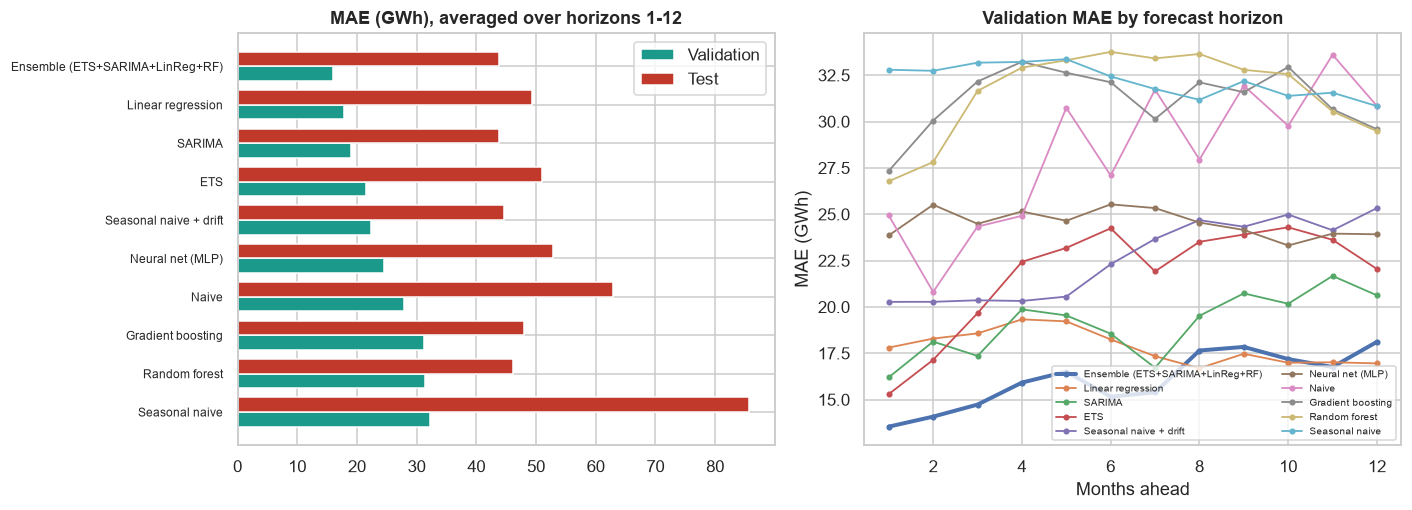


MAE (GWh) at 1,3,6,12 months ahead - DEVELOPMENT
                                  h=1   h=3   h=6  h=12
model                                                  
Ensemble (ETS+SARIMA+LinReg+RF)  13.5  14.7  15.2  18.1
Linear regression                17.8  18.6  18.2  17.0
SARIMA                           16.2  17.4  18.6  20.6
ETS                              15.3  19.7  24.2  22.0
Seasonal naive + drift           20.3  20.4  22.3  25.3
Neural net (MLP)                 23.9  24.5  25.5  23.9
Naive                            24.9  24.3  27.1  30.8
Gradient boosting                27.3  32.2  32.1  29.6
Random forest                    26.8  31.7  33.8  29.5
Seasonal naive                   32.8  33.2  32.4  30.8

MAE (GWh) at 1,3,6,12 months ahead - TEST
                                  h=1   h=3   h=6  h=12
model                                                  
Ensemble (ETS+SARIMA+LinReg+RF)  34.3  38.2  43.8  54.6
Linear regression                41.9  44.7  48.9  55.0
SARIMA     

In [26]:
order = val["model"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
w = .38; x = np.arange(len(order))
axes[0].barh(x + w/2, val.set_index("model").loc[order, "MAE"], w, color=TEAL, label="Validation")
axes[0].barh(x - w/2, tst.set_index("model").loc[order, "MAE"], w, color=RED, label="Test")
axes[0].set_yticks(x); axes[0].set_yticklabels(order, fontsize=8); axes[0].invert_yaxis(); axes[0].legend()
axes[0].set_title("MAE (GWh), averaged over horizons 1-12")
for win, ax in zip(["development", "test"], [axes[1], None]):
    pass
mh = pc.metrics(res[res.window == "development"], ["model", "h"]).pivot(index="h", columns="model", values="MAE")
for mname in order:
    axes[1].plot(mh.index, mh[mname], marker="o", ms=3, lw=2.6 if mname == ENS else 1.2, label=mname)
axes[1].set_title("Validation MAE by forecast horizon"); axes[1].set_xlabel("Months ahead"); axes[1].set_ylabel("MAE (GWh)")
axes[1].legend(fontsize=6.5, ncol=2)
savefig("07_model_comparison"); plt.show()

# Metric table by horizon for the four headline horizons
tab = pc.metrics(res, ["window", "model", "h"])
for win in ["development", "test"]:
    t = tab[(tab.window == win) & tab.h.isin([1, 3, 6, 12])].pivot(index="model", columns="h", values="MAE").round(1)
    t.columns = [f"h={c}" for c in t.columns]
    print(f"\nMAE (GWh) at 1,3,6,12 months ahead - {win.upper()}"); print(t.loc[order].to_string())
mape_t = pc.metrics(res[res.window == "test"], ["model", "h"]).pivot(index="model", columns="h", values="MAPE").round(1)[[1, 3, 6, 12]]
print("\nMAPE (%) at 1,3,6,12 months ahead - TEST"); print(mape_t.loc[order].to_string())

**Reading the charts and tables.** Errors grow with the forecast horizon for most models - the ensemble's validation MAE rises from 13.5 GWh at 1 month ahead to 18.1 GWh at 12 months ahead. Plain seasonal naive is flat across horizons because it always uses the same 12-month-old value. Notice that in validation the **ensemble is best at every horizon from 1 to 6 months**, while linear regression takes over at 12 months - a long-horizon forecast depends mainly on getting the trend right, which a straight-line trend does well.

## 7.1 Do the complex models give a *meaningful* improvement?
Lower MAE is not the same as a *reliably* better model; with few observations differences can be luck. The **Diebold-Mariano test** compares two models' forecast errors and asks whether their difference is statistically distinguishable from zero.

In [27]:
rows = []
base_models = ["Seasonal naive", "Seasonal naive + drift"]
for h in [1, 3, 6]:
    sub = res[res.h == h]
    wide = sub.pivot(index="target_date", columns="model", values="error")
    for m in order:
        for b in base_models:
            if m == b: continue
            stat, p = pc.dm_test(wide[m], wide[b], h=h)
            rows.append([h, m, b, wide[m].abs().mean() - wide[b].abs().mean(), stat, p])
dm = pd.DataFrame(rows, columns=["h", "model", "vs", "MAE_diff_GWh", "DM_stat", "p_value"])
# negative MAE_diff / DM_stat => model beats the baseline
print("Diebold-Mariano tests (all validation + test months pooled).  Negative = model more accurate than the baseline.")
print("p < 0.05 means the improvement is statistically distinguishable from luck.\n")
def fmt(sub):
    out = sub.assign(cell=lambda x: x["MAE_diff_GWh"].map("{:+.1f}".format) + " (p=" + x["p_value"].map("{:.2f}".format) + ")")
    t = out.pivot(index="model", columns="h", values="cell"); t.columns = [f"h={c}" for c in t.columns]; return t.loc[[m for m in order if m in t.index]]
print("MAE difference vs the baseline in GWh (negative = model is better) and DM p-value:\n")
print("vs the STRONGEST simple baseline (seasonal naive + drift):"); print(fmt(dm[dm["vs"] == "Seasonal naive + drift"]).to_string())
print("\nvs plain seasonal naive:"); print(fmt(dm[dm["vs"] == "Seasonal naive"]).to_string())
dm.to_csv("outputs/diebold_mariano.csv", index=False)

Diebold-Mariano tests (all validation + test months pooled).  Negative = model more accurate than the baseline.
p < 0.05 means the improvement is statistically distinguishable from luck.

MAE difference vs the baseline in GWh (negative = model is better) and DM p-value:

vs the STRONGEST simple baseline (seasonal naive + drift):
                                            h=1             h=3             h=6
model                                                                          
Ensemble (ETS+SARIMA+LinReg+RF)   -4.4 (p=0.08)   -3.9 (p=0.19)   -4.3 (p=0.30)
Linear regression                 +0.8 (p=0.79)   +0.8 (p=0.82)   -0.5 (p=0.92)
SARIMA                            -2.4 (p=0.49)   -1.7 (p=0.69)   -1.9 (p=0.73)
ETS                               -2.6 (p=0.44)   +1.1 (p=0.81)   +5.0 (p=0.46)
Neural net (MLP)                  +7.4 (p=0.01)   +7.5 (p=0.02)   +6.2 (p=0.24)
Naive                             +8.7 (p=0.03)   +6.7 (p=0.07)  +10.2 (p=0.15)
Gradient boosting            

**Findings:**
* **Against plain seasonal naive,** the ensemble, linear regression, SARIMA, ETS and the drift baseline are all significantly better (p < 0.05 at almost every horizon). Using last year's value without any growth adjustment is simply not good enough in a growing market.
* **Against the strong drift baseline, no model is significantly better.** The ensemble's improvement is about 4 GWh (p = 0.08 at 1 month ahead, p = 0.19 at 3 months). The random forest, gradient boosting and the neural net are in fact *significantly worse* than the drift baseline.

**Conclusion for the reviewer's question:** more complex machine-learning and neural models offer **no meaningful improvement** over a well-built simple benchmark on this dataset. The only consistent gain comes from **combining** the statistical models, and even that is modest. This is the expected result for a short, trending monthly series, and it is why the project does not assume a complex model is better.

## 7.2 Actual vs predicted
The first figure compares the 3-month-ahead forecast of **every model** with actual sales; the second shows what each model predicted in a single forecast made in December 2024 for the whole of 2025.

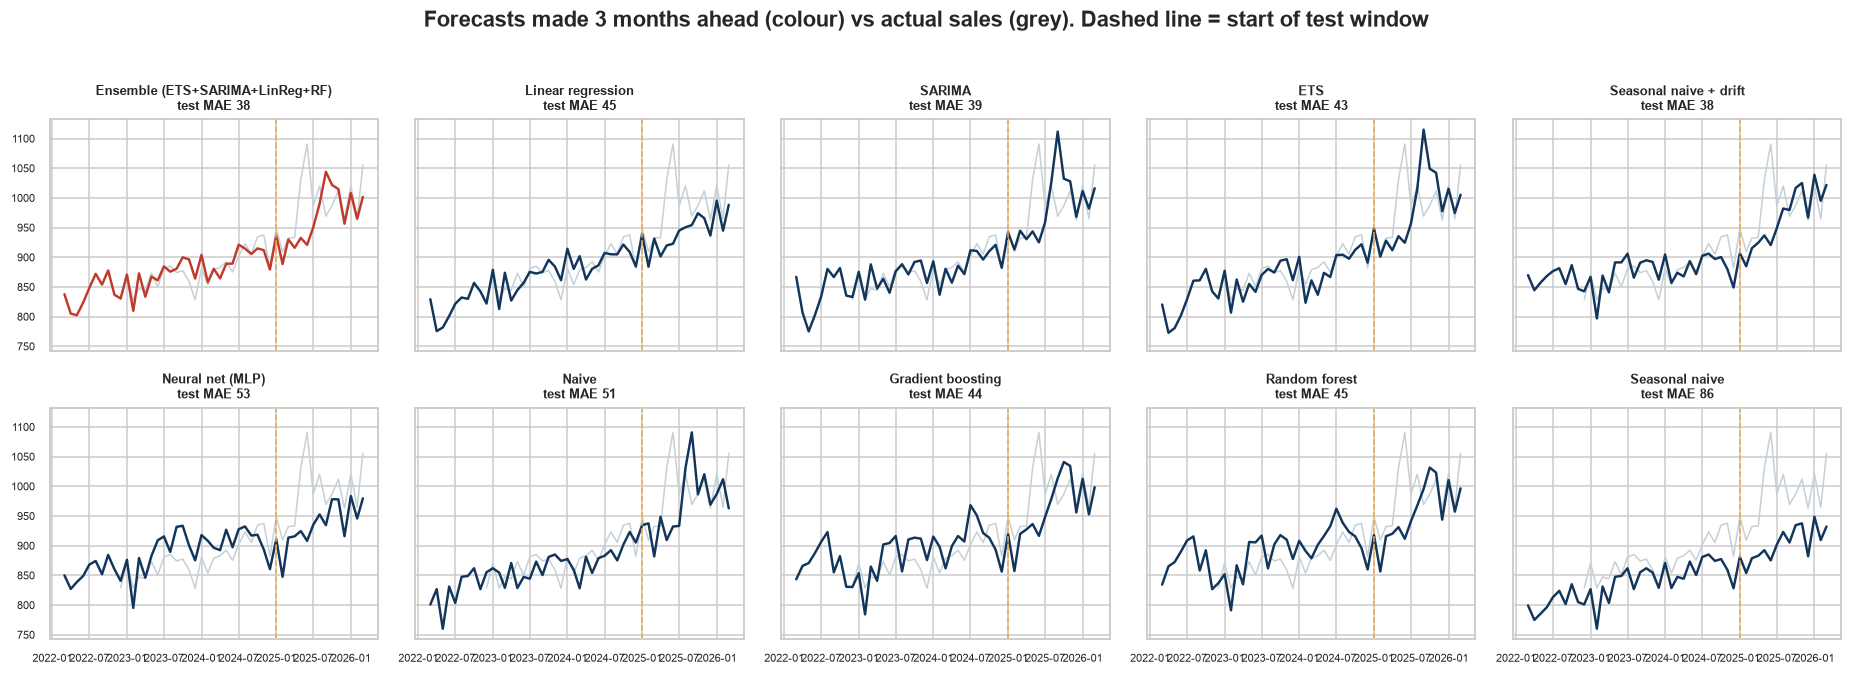

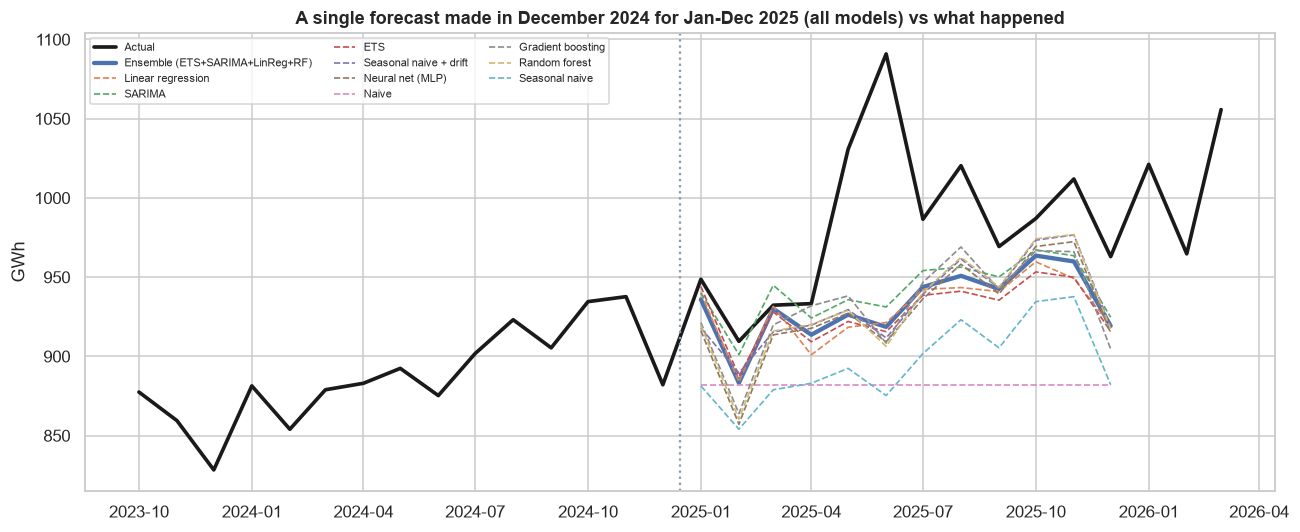

12-month MAE of the Dec-2024 forecast:
model
SARIMA                             42.9
Seasonal naive + drift             48.9
Ensemble (ETS+SARIMA+LinReg+RF)    49.6
Gradient boosting                  50.4
Random forest                      51.4
Linear regression                  52.7
ETS                                53.6
Neural net (MLP)                   54.3
Seasonal naive                     86.2
Naive                              99.9


In [28]:
# Actual vs predicted at a 3-month horizon - EVERY model, test window
h = 3
fig, axes = plt.subplots(2, 5, figsize=(17, 6), sharey=True, sharex=True)
for ax, m in zip(axes.ravel(), order):
    s = res[(res.model == m) & (res.h == h)].sort_values("target_date")
    ax.plot(y.index[-40:], y.values[-40:], color="#c5d0d8", lw=1)
    ax.plot(s["target_date"], s["forecast"], color=RED if m == ENS else NAVY, lw=1.6)
    mae_t = s[s.window == "test"]["error"].abs().mean()
    ax.set_title(f"{m}\ntest MAE {mae_t:.0f}", fontsize=8.5); ax.tick_params(labelsize=7)
    ax.axvline(pd.Timestamp("2025-01-01"), color=AMBER, ls="--", lw=1)
fig.suptitle("Forecasts made 3 months ahead (colour) vs actual sales (grey). Dashed line = start of test window", y=1.02, fontweight="bold")
savefig("08_actual_vs_predicted_all"); plt.show()

# Fixed-origin forecast made in Dec-2024 for the whole of 2025
o = pc.DEV_END_IDX
fo = res[(res.origin_idx == o)].pivot(index="target_date", columns="model", values="forecast")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index[-30:], y.values[-30:], color="k", lw=2.4, label="Actual")
for m in order:
    ax.plot(fo.index, fo[m], lw=2.8 if m == ENS else 1.1, ls="-" if m == ENS else "--", label=m)
ax.axvline(pd.Timestamp("2024-12-15"), color=GREY, ls=":")
ax.set_title("A single forecast made in December 2024 for Jan-Dec 2025 (all models) vs what happened")
ax.set_ylabel("GWh"); ax.legend(fontsize=7, ncol=3)
savefig("09_forecast_dec2024"); plt.show()
fo_err = (fo.sub(y.loc[fo.index], axis=0)).abs().mean().sort_values()
print("12-month MAE of the Dec-2024 forecast:"); print(fo_err.round(1).to_string())

**Findings.** All models track the *shape* of the year (the seasonal ups and downs) well through April 2025. From May 2025 every model - without exception - falls below the actual line, because none of them could anticipate the May-June jump and the higher level that followed. The 12-month MAE of the December 2024 forecast ranged from 43 GWh (SARIMA, the model that adapts fastest) to 100 GWh (naive).

## 7.3 Error analysis - where and why do the models fail?

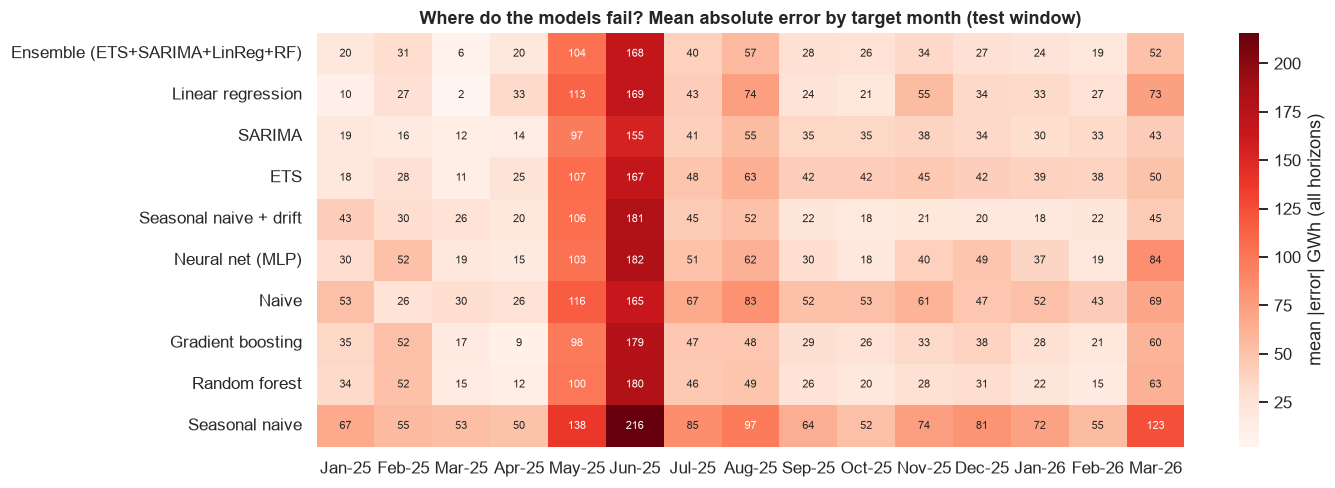

Months where the ensemble errs most (mean |error|, all horizons):
target_date
2025-06-01    168.0
2025-05-01    104.1
2025-08-01     56.8
2026-03-01     51.9
2025-07-01     40.4

Test-window bias (actual - forecast, GWh). Positive = models UNDER-forecast:
                                 Bias
model                                
Ensemble (ETS+SARIMA+LinReg+RF)  34.5
Linear regression                49.2
SARIMA                           21.9
ETS                              26.1
Seasonal naive + drift           38.1
Neural net (MLP)                 52.8
Naive                            43.0
Gradient boosting                38.1
Random forest                    40.6
Seasonal naive                   85.7

Ensemble validation MAE by calendar month of the target:
target_date
1     17.5
2     18.3
3     16.2
4      8.4
5     12.9
6     18.6
7     11.3
8     17.9
9     10.2
10    16.3
11    25.6
12    16.6


In [29]:
t = res[res.window == "test"].copy()
t["abs_err"] = t["error"].abs()
heat = t.pivot_table(index="model", columns=t["target_date"].dt.strftime("%b-%y"), values="abs_err", aggfunc="mean")
heat = heat[[c for c in pd.Series(sorted(t["target_date"].unique())).dt.strftime("%b-%y")]].loc[order]
fig, ax = plt.subplots(figsize=(13, 4.6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds", ax=ax, cbar_kws={"label": "mean |error| GWh (all horizons)"}, annot_kws={"size": 7})
ax.set_title("Where do the models fail? Mean absolute error by target month (test window)"); ax.set_xlabel(""); ax.set_ylabel("")
savefig("10_error_heatmap"); plt.show()

worst = t[t.model == ENS].groupby("target_date")["abs_err"].mean().nlargest(5).round(1)
print("Months where the ensemble errs most (mean |error|, all horizons):"); print(worst.to_string())

bias = pc.metrics(res[res.window == "test"], ["model"])[["model", "Bias"]].set_index("model").loc[order]
print("\nTest-window bias (actual - forecast, GWh). Positive = models UNDER-forecast:"); print(bias.round(1).to_string())

# error by calendar month, validation window
dv = res[(res.window == "development") & (res.model == ENS)].copy()
dv["abs_err"] = dv["error"].abs()
print("\nEnsemble validation MAE by calendar month of the target:")
print(dv.groupby(dv["target_date"].dt.month)["abs_err"].mean().round(1).to_string())

**Findings.**
* **Errors are concentrated in a few months.** The ensemble's largest errors are **June 2025 (168 GWh average), May 2025 (104 GWh)**, then August 2025 (57) and March 2026 (52). The heat map shows that *every* model fails in the same months, so this is a data/regime problem, not a modelling choice.
* **All models under-forecast in the test window** (average bias of +22 to +86 GWh, i.e. actual sales exceeded forecasts), because growth accelerated.
* In validation, the largest errors by month are for **November (26 GWh)** and the smallest for **April (8 GWh)**; there is no strong calendar pattern.

## 7.4 Sensitivity: how much do May-June 2025 matter?
We re-ran the chosen models on the sensitivity series (those two months replaced) and compared test errors.

In [30]:
# Sensitivity: rerun the chosen models on the series with May/Jun-2025 replaced (see earlier section)
chosen_models = {k: pc.candidate_models()[v] for k, v in chosen.items()}
chosen_models.update({k: pc.candidate_models()[k] for k in ["Naive", "Seasonal naive", "Seasonal naive + drift", "Linear regression"]})
res_adj = pc.rolling_origin(y_adj, chosen_models, verbose=False)
res_adj = pc.add_ensemble(res_adj, MEMBERS)
cmp_s = pd.DataFrame({
    "MAE test - reported series": pc.metrics(res[(res.window == "test") & res.model.isin(res_adj.model.unique())], ["model"]).set_index("model")["MAE"],
    "MAE test - sensitivity series": pc.metrics(res_adj[res_adj.window == "test"], ["model"]).set_index("model")["MAE"],
}).round(1).sort_values("MAE test - sensitivity series")
cmp_s["rank (reported)"] = cmp_s["MAE test - reported series"].rank().astype(int)
cmp_s["rank (sensitivity)"] = cmp_s["MAE test - sensitivity series"].rank().astype(int)
print("Test-window MAE (GWh) with and without the May/Jun-2025 anomaly:"); print(cmp_s.to_string())

Test-window MAE (GWh) with and without the May/Jun-2025 anomaly:
                                 MAE test - reported series  MAE test - sensitivity series  rank (reported)  rank (sensitivity)
model                                                                                                                          
SARIMA                                                 43.8                           24.1                1                   1
ETS                                                    51.1                           28.3                6                   2
Ensemble (ETS+SARIMA+LinReg+RF)                        43.8                           28.7                1                   3
Seasonal naive + drift                                 44.6                           29.3                3                   4
Random forest                                          46.1                           31.7                4                   5
Linear regression                      

**Findings.**
* Removing the anomaly cuts every model's test MAE by roughly 13-23 GWh (for example SARIMA 43.8 -> 24.1; ensemble 43.8 -> 28.7). **Those two months explain a large share of the test-window error.**
* **The conclusions that matter hold up:** SARIMA stays first; the two naive baselines remain the worst performers; the drift baseline stays competitive. The ranking among the top models does shift (ETS moves to 2nd and the ensemble to 3rd), which is a reminder not to over-interpret small gaps between top models.

---
# Stage 8 - Uncertainty and explainability

## 8.1 Forecast uncertainty
A forecast without a range overstates certainty. We build **empirical prediction intervals**: the half-width at each horizon is the 80th percentile of the model's past absolute errors at that horizon (calibrated on the validation window only), and we then check how often the test-window actuals really fell inside.

In [31]:
# Empirical prediction intervals: width at horizon h = 80th percentile of past |errors| at horizon h
ens_all = res[res.model == ENS]
calib = ens_all[ens_all.window == "development"]
evalw = ens_all[ens_all.window == "test"]
cov = pc.interval_coverage(calib, evalw, 0.8)
q80 = pc.interval_table(calib, 0.8)
print("Interval half-width (GWh) calibrated on VALIDATION errors, and its coverage on the TEST window:")
print(pd.DataFrame({"half_width_80%": q80.round(1), "test_coverage": cov.round(2)}).T.to_string())
print(f"\nNominal coverage 80%; achieved on test, averaged over horizons: {cov.mean():.0%}")
SLIDE["test_cov_80"] = float(cov.mean())

# also for a few other models (honesty check that under-coverage is not specific to the ensemble)
cov_all = {m: pc.interval_coverage(res[(res.model == m) & (res.window == "development")],
                                    res[(res.model == m) & (res.window == "test")], 0.8).mean() for m in order}
print("\n80% interval coverage on test, by model:"); print(pd.Series(cov_all).round(2).sort_values().to_string())

Interval half-width (GWh) calibrated on VALIDATION errors, and its coverage on the TEST window:
h                  1      2      3     4      5     6     7     8      9      10     11     12
half_width_80%  22.40  24.10  23.70  26.4  25.20  26.9  22.7  24.8  26.20  25.70  27.70  28.30
test_coverage    0.53   0.53   0.53   0.6   0.53   0.6   0.2   0.4   0.33   0.27   0.27   0.27

Nominal coverage 80%; achieved on test, averaged over horizons: 42%

80% interval coverage on test, by model:
Seasonal naive                     0.09
Linear regression                  0.38
Naive                              0.41
Ensemble (ETS+SARIMA+LinReg+RF)    0.42
Neural net (MLP)                   0.46
ETS                                0.52
SARIMA                             0.52
Seasonal naive + drift             0.59
Gradient boosting                  0.61
Random forest                      0.63


**Finding - an important warning.** On validation-calibrated intervals the half-width is only 22-28 GWh, but **only about 42% of test months fell inside the nominal "80%" interval.** The intervals were too narrow because the test period contains a regime change that the validation errors did not contain. The same under-coverage affects every model. For the real forecast we therefore calibrate the intervals on *all* available rolling-origin errors (validation + test), which widens them, and we still advise users to treat the intervals as **optimistic**.

## 8.2 Explaining each model to its users
### Linear regression - the clearest explanation
Every coefficient is in GWh, so it can be read directly: a trend per month and the difference of each calendar month from January.

Linear-regression: intercept 718.4 GWh (Jan-2019 level)
trend (GWh per month)     3.41
Feb vs Jan              -55.50
Mar vs Jan              -10.83
Apr vs Jan              -48.22
May vs Jan              -22.82
Jun vs Jan              -15.08
Jul vs Jan              -15.50
Aug vs Jan              -13.05
Sep vs Jan              -25.95
Oct vs Jan              -10.68
Nov vs Jan              -19.55
Dec vs Jan              -55.44
leap-year February        8.36


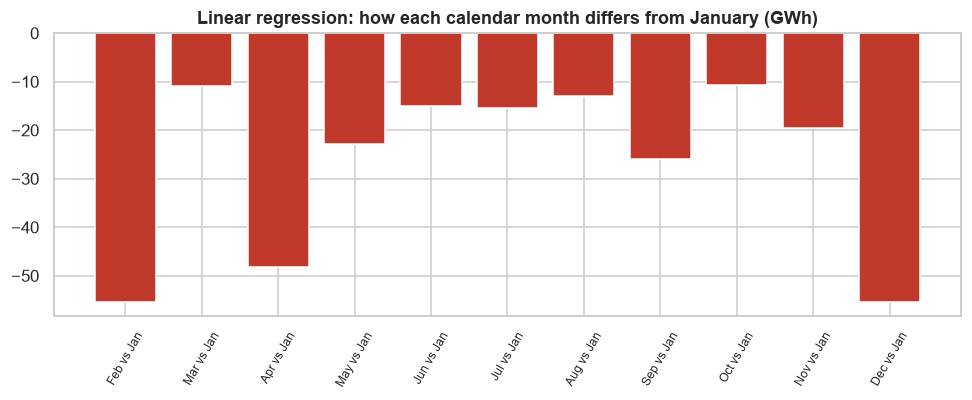

In [32]:
from sklearn.linear_model import LinearRegression
Xl = pc._cal_features(y.index, y.index[0])
lin = LinearRegression().fit(Xl, y.values)
names = ["trend (GWh per month)"] + [f"{pd.Timestamp(2001, m, 1):%b} vs Jan" for m in range(2, 13)] + ["leap-year February"]
coef = pd.Series(np.r_[lin.coef_], index=names)
print(f"Linear-regression: intercept {lin.intercept_:.1f} GWh (Jan-2019 level)")
print(coef.round(2).to_string())
fig, ax = plt.subplots(figsize=(9, 3.8))
c = coef.iloc[1:-1]; ax.bar(c.index, c.values, color=[TEAL if v >= 0 else RED for v in c.values])
ax.set_title("Linear regression: how each calendar month differs from January (GWh)"); ax.tick_params(axis="x", rotation=60, labelsize=8)
savefig("11_linreg_coefficients"); plt.show()

Every coefficient reads directly as GWh. The trend term says sales rose by about **3.4 GWh each month (about 41 GWh a year)** on average over 2019-2026; the other terms show how each month differs from January. **February and December are the lowest months (about 55 GWh below January)** and April is about 48 GWh below.

### ETS - level, trend and seasonality
ETS describes the series with a current level, a trend and a set of seasonal indices.

In [33]:
a, info = pc._ets_forecast(y, damped=(chosen["ETS"] == "ETS_damped"))
print("ETS configuration chosen:", chosen["ETS"])
print({k: (round(float(v), 3) if np.isscalar(v) else None) for k, v in info.items() if k != "seasonal"})
print("\nSeasonal indices (GWh) for Jan..Dec as at the last observation:")
si = pd.Series(info["seasonal"], index=pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS").strftime("%b"))
print(si.round(1).to_string())
print(f"\nCurrent level {info['level']:.1f} GWh, trend {info['trend']:+.2f} GWh/month ({info['trend']*12:+.1f} GWh per year)")

ETS configuration chosen: ETS_undamped
{'alpha': 0.5, 'beta_star': 0.026, 'gamma_star': 0.315, 'phi': 1.0, 'level': 1021.021, 'trend': 3.807}

Seasonal indices (GWh) for Jan..Dec as at the last observation:
Apr    -8.3
May    14.2
Jun     8.7
Jul     0.1
Aug    11.0
Sep    -3.7
Oct    15.7
Nov    16.9
Dec   -23.4
Jan    31.2
Feb   -26.2
Mar    17.1

Current level 1021.0 GWh, trend +3.81 GWh/month (+45.7 GWh per year)


ETS describes the series with three moving parts: the current *level* (about 1,021 GWh), the *trend* (about +3.8 GWh per month, or +46 GWh per year) and a set of *seasonal indices* (e.g. December about 23 GWh below the level-plus-trend, January about 31 GWh above). The smoothing parameters show how fast it adapts: alpha = 0.5 means the level reacts quickly to new data, while the small trend parameter means growth is estimated slowly.

### Random forest - which inputs matter?
We examine two measures of importance: impurity importance (how much the trees use each input) and permutation importance (how much accuracy drops on unseen test rows when an input is scrambled).

Random forest trained on 402 (origin,horizon) rows with targets <= Dec-2024; evaluated on 180 rows with test-window targets.
                    impurity importance  permutation importance (MAE increase, log-growth units)
yoy_growth_mean_6m               0.2333                                                   0.0006
horizon                          0.1662                                                   0.0008
yoy_growth_t0                    0.1569                                                   0.0003
month_cos                        0.1237                                                  -0.0001
yoy_momentum                     0.0982                                                   0.0002
month_sin                        0.0865                                                  -0.0003
yoy_growth_t-2                   0.0718                                                   0.0001
yoy_growth_t-1                   0.0634                                                   0.0001


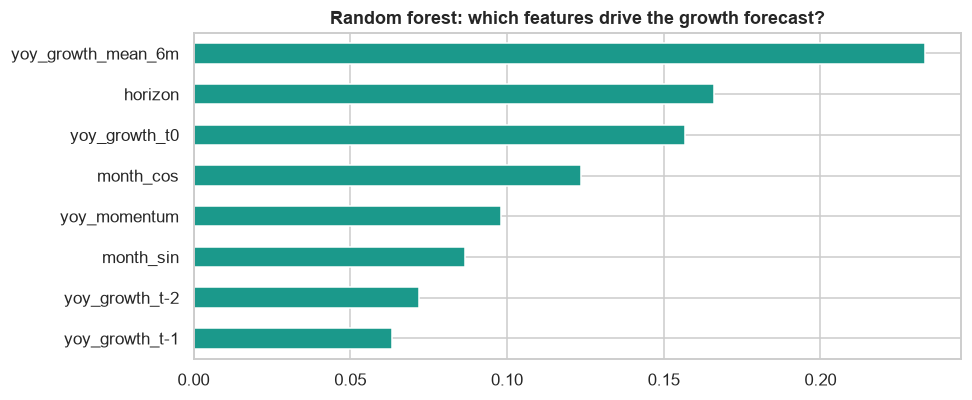

In [34]:
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestRegressor
u = (y / y.index.days_in_month).values
fut = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
Xd, Yd, Td = pc._direct_xy(u, y.index.append(fut), return_t=True)
tr, te = Td <= pc.DEV_END_IDX, Td >= pc.TEST_START_IDX
rf = RandomForestRegressor(n_estimators=150, max_depth=(3 if chosen["Random forest"] == "RF_depth3" else None),
                           min_samples_leaf=3, random_state=42).fit(Xd[tr], Yd[tr])
imp_mdi = pd.Series(rf.feature_importances_, index=pc.FEATURE_NAMES)
pi = permutation_importance(rf, Xd[te], Yd[te], n_repeats=30, random_state=0, scoring="neg_mean_absolute_error")
imp_perm = pd.Series(pi.importances_mean, index=pc.FEATURE_NAMES)
print(f"Random forest trained on {tr.sum()} (origin,horizon) rows with targets <= Dec-2024; evaluated on {te.sum()} rows with test-window targets.")
tab = pd.DataFrame({"impurity importance": imp_mdi, "permutation importance (MAE increase, log-growth units)": imp_perm}).sort_values("impurity importance", ascending=False)
print(tab.round(4).to_string())
fig, ax = plt.subplots(figsize=(9, 3.8)); tab["impurity importance"].sort_values().plot.barh(color=TEAL, ax=ax)
ax.set_title("Random forest: which features drive the growth forecast?"); savefig("12_rf_importance"); plt.show()

The random forest predicts year-on-year growth. **Impurity importance** (how much each input is used inside the trees) shows that the most-used inputs are the **6-month average growth (23%)**, the **forecast horizon (17%)** and the **latest growth rate (16%)**, with the calendar-month terms together about 21%. In plain language: *the forest mostly extrapolates recent growth and adjusts it a little for the month of the year.* **Permutation importance** on test rows is very small for every feature, which tells us the forest's growth adjustments add little beyond "same month last year" - consistent with its weak result in the Diebold-Mariano tests. An honest reading is that the random forest has too little data (402 training rows built from only about five years of usable monthly growth rates) to learn much more than a seasonal baseline.

## 8.3 The forecast
The **final model is the ensemble**, chosen by the pre-declared rule "lowest validation MAE" (and it is still joint-best on the test window). All members are re-fitted on all 87 months to forecast April 2026 - March 2027.

12-month-ahead forecast, Apr-2026 to Mar-2027 (GWh):
            Ensemble (ETS+SARIMA+LinReg+RF)  lower_80  upper_80  lower_90  upper_90  implied_yoy_%  ensemble_if_MayJun2025_are_one_offs
date                                                                                                                                   
2026-04-01                           1003.6     978.6    1028.5     965.0    1042.1            7.5                                999.7
2026-05-01                           1054.8    1025.9    1083.7    1021.3    1088.3            2.3                               1018.6
2026-06-01                           1104.2    1072.2    1136.3    1059.1    1149.3            1.2                               1006.2
2026-07-01                           1044.3    1011.3    1077.3     998.3    1090.3            5.9                               1042.9
2026-08-01                           1058.4    1029.3    1087.6    1015.1    1101.8            3.7                               10

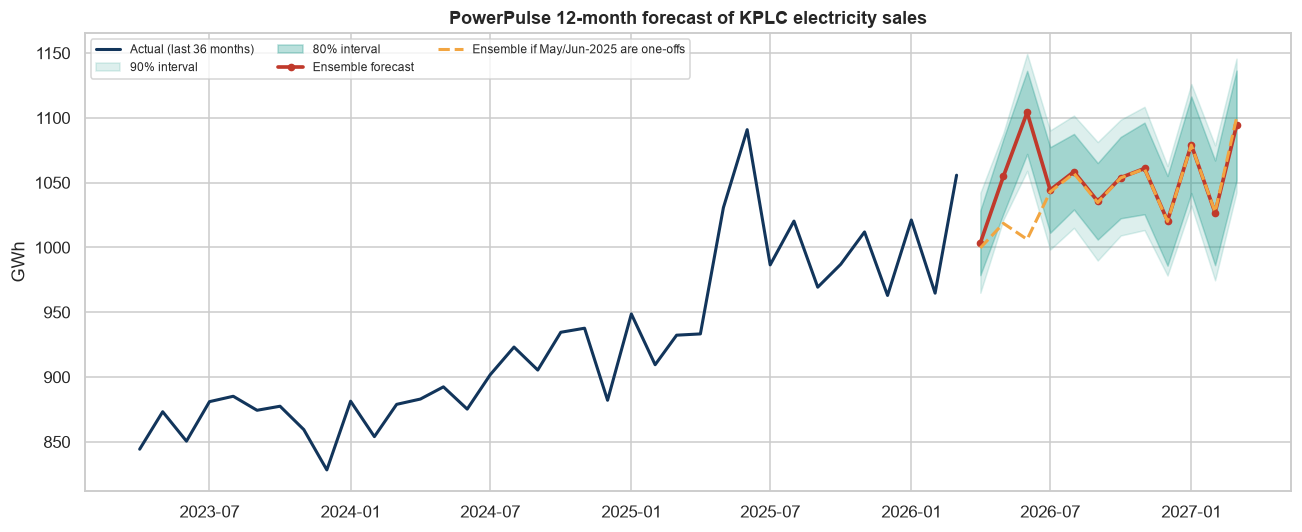

In [35]:
fut_dates = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
final = {}
for fam in MEMBERS:
    key = chosen.get(fam, fam)
    final[fam] = pc.candidate_models()[key](y)
for other in ["Naive", "Seasonal naive", "Seasonal naive + drift", "Gradient boosting", "Neural net (MLP)"]:
    final[other] = pc.candidate_models()[other](y)
fc = pd.DataFrame(final, index=fut_dates)
fc[ENS] = fc[MEMBERS].mean(axis=1)
q80_all = pc.interval_table(ens_all, 0.80); q90_all = pc.interval_table(ens_all, 0.90)
fc["lower_80"] = fc[ENS].values - q80_all.values; fc["upper_80"] = fc[ENS].values + q80_all.values
fc["lower_90"] = fc[ENS].values - q90_all.values; fc["upper_90"] = fc[ENS].values + q90_all.values
fc["same_month_last_year"] = [y.get(d - pd.DateOffset(years=1), np.nan) for d in fut_dates]
fc["implied_yoy_%"] = (fc[ENS] / fc["same_month_last_year"] - 1) * 100
final_adj = pd.DataFrame({fam: pc.candidate_models()[chosen.get(fam, fam)](y_adj) for fam in MEMBERS}, index=fut_dates)
fc["ensemble_if_MayJun2025_are_one_offs"] = final_adj.mean(axis=1)
fc.index.name = "date"
fc.round(1).to_csv("outputs/final_forecast_next_12_months.csv")
print("12-month-ahead forecast, Apr-2026 to Mar-2027 (GWh):")
print(fc[[ENS, "lower_80", "upper_80", "lower_90", "upper_90", "implied_yoy_%", "ensemble_if_MayJun2025_are_one_offs"]].round(1).to_string())
last12 = y.iloc[-12:].sum(); next12 = fc[ENS].sum(); next12_adj = fc["ensemble_if_MayJun2025_are_one_offs"].sum()
print(f"\nLast 12 months actual (Apr-25..Mar-26): {last12:,.0f} GWh | next 12 months forecast: {next12:,.0f} GWh ({(next12/last12-1)*100:+.1f}%) "
      f"| if May/Jun-2025 were one-offs: {next12_adj:,.0f} GWh ({(next12_adj/last12-1)*100:+.1f}%)")
SLIDE["last12"], SLIDE["next12"], SLIDE["next12_adj"] = float(last12), float(next12), float(next12_adj)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index[-36:], y.values[-36:], color=NAVY, lw=2, label="Actual (last 36 months)")
ax.fill_between(fc.index, fc["lower_90"], fc["upper_90"], color=TEAL, alpha=.15, label="90% interval")
ax.fill_between(fc.index, fc["lower_80"], fc["upper_80"], color=TEAL, alpha=.30, label="80% interval")
ax.plot(fc.index, fc[ENS], color=RED, lw=2.4, marker="o", ms=4, label="Ensemble forecast")
ax.plot(fc.index, fc["ensemble_if_MayJun2025_are_one_offs"], color=AMBER, lw=2, ls="--", label="Ensemble if May/Jun-2025 are one-offs")
ax.set_title("PowerPulse 12-month forecast of KPLC electricity sales"); ax.set_ylabel("GWh"); ax.legend(fontsize=8, ncol=3)
savefig("13_final_forecast"); plt.show()

**Reading the forecast.**
* The ensemble expects about **12,636 GWh over the next 12 months, +5.0% vs the last 12 months (12,035 GWh)**, in line with the 4-5% typical of 2022-2024 and below the exceptional 2025 rate.
* **Caveat on May-June 2026.** The models treat May-June 2025 as normal seasonal highs and therefore forecast another spike (June 2026: 1,104 GWh; implied growth only +1.2%). If those two months were one-offs, the forecast is nearer **1,019 and 1,006 GWh**, and the annual total is **12,500 GWh (+3.9%)**. The dashed amber line on the chart shows this alternative; planners should treat the gap as a scenario range rather than pick one.
* The March 2026 observation is provisional and may be revised by KNBS.

## 8.4 Cross-check against statsmodels (optional)

In [36]:
# Optional cross-check against statsmodels (only runs if it is installed in YOUR environment)
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    hist = y.iloc[:-12]
    sm_f = SARIMAX(hist, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(12)
    my_f = pd.Series(pc._mk_sarima("SARIMA_B")(hist), index=sm_f.index)
    hw = ExponentialSmoothing(hist, trend="add", seasonal="add", seasonal_periods=12).fit()
    print("statsmodels cross-check (history up to", hist.index[-1].date(), ")")
    print("SARIMA(1,1,1)(0,1,1)12  mean |difference| vs this project's implementation: %.1f GWh" % (sm_f - my_f).abs().mean())
    print("Holt-Winters mean |difference| vs this project's ETS: %.1f GWh" % np.abs(hw.forecast(12).values - pc._ets_forecast(hist, False)[0]).mean())
except ImportError:
    print("statsmodels is not installed here - cross-check skipped (the project does not depend on it).")

statsmodels cross-check (history up to 2025-03-01 )
SARIMA(1,1,1)(0,1,1)12  mean |difference| vs this project's implementation: 3.7 GWh
Holt-Winters mean |difference| vs this project's ETS: 3.4 GWh


## 8.5 Saving results for the dashboard and slides

In [37]:
res.to_csv("outputs/rolling_origin_forecasts.csv", index=False)
allm = pc.metrics(res, ["window", "model", "h"], scale=SC)
allm.to_csv("outputs/model_metrics_by_horizon.csv", index=False)
summ = pd.concat([val.assign(window="validation"), tst.assign(window="test")])
summ.to_csv("outputs/model_metrics_summary.csv", index=False)
dec.reset_index().rename(columns={"index": "date"}).to_csv("outputs/decomposition.csv", index=False)
pd.DataFrame({"feature": pc.FEATURE_NAMES, "impurity_importance": imp_mdi.values,
              "permutation_importance": imp_perm.values}).to_csv("outputs/rf_feature_importance.csv", index=False)
coef.rename("coefficient").rename_axis("term").reset_index().to_csv("outputs/linreg_coefficients.csv", index=False)
pd.DataFrame({"half_width_80_validation": q80, "test_coverage_80": cov}).rename_axis("h").reset_index().to_csv("outputs/interval_calibration.csv", index=False)
cmp_s.rename_axis("model").reset_index().to_csv("outputs/sensitivity_may_june_2025.csv", index=False)
d.reset_index().to_csv("outputs/eda_growth_table.csv", index=False)
triage.to_csv("outputs/file_triage.csv", index=False)
SLIDE.update({
    "chosen": chosen, "ens": ENS, "n_obs": int(len(y)),
    "val": val.round(2).to_dict("records"), "test": tst.round(2).to_dict("records"),
    "by_h_test": allm[(allm.window == "test")].pivot(index="model", columns="h", values="MAE").round(1).to_dict("index"),
    "by_h_dev": allm[(allm.window == "development")].pivot(index="model", columns="h", values="MAE").round(1).to_dict("index"),
    "forecast": fc[[ENS, "lower_80", "upper_80", "lower_90", "upper_90", "ensemble_if_MayJun2025_are_one_offs"]].round(1).reset_index().assign(date=lambda x: x["date"].dt.strftime("%Y-%m")).to_dict("records"),
    "annual": annual.reset_index().to_dict("records"),
    "seasonal_effect": seas.round(1).to_dict(), "feature_importance": imp_mdi.round(4).to_dict(),
    "sens": cmp_s.reset_index().rename(columns={"index": "model"}).to_dict("records"),
    "interval_cov": cov.round(2).to_dict(), "mase_scale": SC,
})
open("outputs/slide_data.json", "w").write(json.dumps(SLIDE, indent=1, default=str).replace("NaN", "null"))
print("Saved artefacts:", sorted(p.name for p in Path("outputs").glob("*.csv")))

Saved artefacts: ['decomposition.csv', 'diebold_mariano.csv', 'eda_growth_table.csv', 'file_triage.csv', 'final_forecast_next_12_months.csv', 'interval_calibration.csv', 'linreg_coefficients.csv', 'model_metrics_by_horizon.csv', 'model_metrics_summary.csv', 'rf_feature_importance.csv', 'rolling_origin_all_candidates.csv', 'rolling_origin_forecasts.csv', 'sensitivity_may_june_2025.csv']


---
# Stage 9 - Conclusions

## Answers to the research questions
**1. What trends and seasonal patterns exist?** A strong upward trend (+32.8% in average monthly sales from 2019 to 2025, about +3.4 GWh each month), interrupted by COVID-19 in 2020 and accelerating in 2025. A statistically significant seasonal pattern (Kruskal-Wallis p = 0.0004) with highs in January, June, August and October and lows in February, April and December - partly (but not entirely) explained by the number of days in the month.

**2. Can the data support accurate forecasts?** Yes, with qualifications. When growth is stable (validation 2022-2024) the best model is off by about **1.8% on average** (15.9 GWh). When growth shifts (test 2025-2026) the error is about **4.3%** (43.8 GWh). Forecasts are good enough for 12-month budgeting if users understand the uncertainty, but not precise enough to treat a single month as exact.

**3. Which models perform best?** On validation: ensemble > linear regression > SARIMA > ETS > seasonal-naive-with-drift > neural net > naive > gradient boosting ~ random forest ~ seasonal naive. On the test window: SARIMA ~ ensemble > drift baseline > random forest > gradient boosting > linear regression > ETS > neural net > naive > seasonal naive.

**4. How do the models compare in errors and generalisation?** Every model's error is much larger on unseen 2025-26 months (about 2.7x for the ensemble). Statistical models that adapt their level (SARIMA, ETS) or combine models generalise best; models with a fixed trend (linear regression) or limited data (random forest, neural net) generalise worse. **Complex ML models do not significantly beat a simple seasonal-naive-with-drift benchmark.**

**5. What insights support planning?** (a) Expect about 12,600 GWh over the next 12 months (about +4% to +5%); (b) plan for seasonal troughs in February, April and December and peaks in October-November and mid-year; (c) allow a margin of about +/-25 to 55 GWh per month (typical errors grow from about 34 GWh at one month ahead to about 55 GWh at twelve, in the test window), and more if regime changes recur; (d) the 2025 sales surge should be investigated with KNBS/KPLC - part of it (May-June) may be a reporting artefact.

## Limitations (stated plainly)
* **Data volume and verification:** 87 months, not the 196 (2010-2026) that the proposal aimed for, and 60 of the 87 are still candidate values awaiting verification against the original KNBS reports. Report revisions between vintages could change some of them.
* **The anomaly:** May-June 2025 cannot be explained from the data available; results are reported both with and without them.
* **Short test window:** 15 test months (with only a single 12-month-ahead fan from each origin) make statistical tests low-powered; the test set also contains a regime shift, so test errors are pessimistic for stable years and optimistic about nothing.
* **Intervals under-cover** in the test window and should be regarded as optimistic.
* **No external drivers** (GDP, weather, tariffs, population or connections) were used; only the sales series itself and 2024-26 supply data.
* **LSTM not implemented** - justified by data size, listed below.

## Recommended next steps
1. Verify the 2019-2023 values against the original KNBS PDFs and record the verified values in the register; reconcile report vintages.
2. Extend the series back to 2010 (and annual Statistical Abstract data) to give the models more than 7 years.
3. Ask KNBS/KPLC whether May-June 2025 contain billing or reporting catch-up.
4. Add external regressors (GDP growth, customer connections, tariffs, rainfall/temperature) and test them with the same rolling-origin protocol.
5. Once more data exist, test an LSTM and a hierarchical or Prophet-style model against the ensemble using exactly this evaluation design.

## Reproducibility
Run the cells top to bottom (about 40 seconds). Files used: `data/` (three source CSVs + reference files), `powerpulse_core.py`, `outputs/` (all results). The dashboard is started with `streamlit run app.py`.